# Lab01 - sprint 1

Команда 13 (КТвД). ISU: 501564, 501235, 458829.

Тема: болиды. Данные из каталога NASA JPL.

Мы выбрали общую тему космоса, потому что космос красивый и там есть множество различных случайных величин. Нельзя предсказать где и когда пролетит очередной метеор. Болид это очень яркий метеор, космический камень влетает в атмосферу и ярко взрывается. Данные, как указано выше, мы берем из открытого каталога NASA. Будем смотреть три величины: сколько дней проходит между соседними болидами, сколько болидов случается за месяц и на какой широте они падают.

In [1]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
#@title Стиль графиков — запустить один раз в начале { display-mode: "form" }
import matplotlib as mpl
import matplotlib.pyplot as plt

# Палитра «космос»: имена переменных не менять, на них опираются остальные ноутбуки
C_DATA   = "#1F4E8C"   # данные — глубокий синий ночного неба
C_THEORY = "#E85D04"   # теоретическая кривая — раскалённый оранжевый болида
C_ACCENT = "#9B5DE5"   # выделение — фиолетовый туманности
C_MUTED  = "#8A94A6"   # второстепенные элементы — серо-голубая дымка
C_PALETTE = [C_DATA, C_THEORY, C_ACCENT, C_MUTED, "#2A9D8F", "#C9184A"]

# Блок Б: размер и разрешение всех картинок
mpl.rcParams.update({
    "figure.figsize": (9, 5.2),    # размер картинки в дюймах
    "figure.dpi": 110,             # качество на экране
    "savefig.dpi": 150,            # качество при сохранении в файл
    "figure.facecolor": "white",   # белый фон вокруг осей
    "axes.facecolor": "white",     # белый фон внутри осей
    "savefig.facecolor": "white",
})

# Блок В: шрифты
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans"],
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
})

# Блок Г: рамки и сетка
mpl.rcParams.update({
    "axes.edgecolor": "#B9C0CC",
    "axes.linewidth": 1.0,
    "axes.spines.top": False,     # убрать верхнюю рамку
    "axes.spines.right": False,   # убрать правую рамку
    "axes.grid": True,
    "axes.axisbelow": True,       # сетка под данными, а не поверх
    "grid.color": "#D9DEE7",
    "grid.linewidth": 0.8,
    "grid.alpha": 0.7,
})

# Блок Д: деления на осях
mpl.rcParams.update({
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.color": "#4A5568",
    "ytick.color": "#4A5568",
})

# Блок Е: линии, легенда и порядок цветов
mpl.rcParams.update({
    "lines.linewidth": 2.0,
    "lines.markersize": 6,
    "legend.frameon": False,      # легенда без рамки
    "legend.fontsize": 10,
    "axes.prop_cycle": mpl.cycler(color=C_PALETTE),  # цвета серий по умолчанию
})

# картинки в двойном разрешении, чтобы подписи были четкие на любом экране
%config InlineBackend.figure_format = "retina"

print("Стиль применён. Палитра:", C_PALETTE)

Стиль применён. Палитра: ['#1F4E8C', '#E85D04', '#9B5DE5', '#8A94A6', '#2A9D8F', '#C9184A']


## Dataset

Откуда данные и что про них пишет NASA:

- страница каталога: https://cneos.jpl.nasa.gov/fireballs/intro.html
- описание полей: https://ssd-api.jpl.nasa.gov/doc/fireball.html

На странице каталога сказано, что вспышки записывают датчики правительства США (U.S. Government sensors) и что список неполный: "This website is not meant to be a complete list of all fireball events. Only the brightest fireballs are noted."

### Загрузка

In [3]:
# каталог болидов NASA JPL, регистрация не нужна
# дату конца фиксируем, чтобы числа в работе не менялись когда в каталог добавят новые болиды
URL = "https://ssd-api.jpl.nasa.gov/fireball.api?date-max=2026-10-31"

answer = requests.get(URL).json()
raw = pd.DataFrame(answer["data"], columns=answer["fields"])
print(raw.shape)
raw.head()

(1074, 9)


,date,energy,impact-e,lat,lat-dir,lon,lon-dir,alt,vel
0,2026-10-04 03:14:45,5.4,0.18,41.8,S,173.1,W,26.9,13.8
1,2026-09-15 11:26:13,2.2,0.079,37.6,S,161.6,W,37.0,NaN
2,2026-09-11 10:18:03,6.1,0.2,0.2,S,129.6,W,70.0,NaN
3,2026-09-11 01:12:11,24.6,0.67,54.4,N,100.1,W,38.0,20.7
4,2026-09-10 05:22:22,11.1,0.33,19.3,S,28.1,W,33.6,19.3


Столбцы (по описанию полей NASA):

- `date` дата и время максимальной яркости вспышки (GMT)
- `energy` излученная энергия, $10^{10}$ Дж
- `impact-e` полная энергия взрыва, килотонны в тротиловом эквиваленте
- `lat`, `lat-dir` широта и полушарие (N или S)
- `lon`, `lon-dir` долгота и полушарие (E или W)
- `alt` высота в момент максимальной яркости, км
- `vel` скорость в момент максимальной яркости, км/с

В первых строках уже видно `NaN` в столбце `vel`, это пропуск: значение неизвестно.

In [4]:
# в каком виде пришли значения
raw.dtypes

date        str
energy      str
impact-e    str
lat         str
lat-dir     str
lon         str
lon-dir     str
alt         str
vel         str
dtype: object

In [5]:
# все столбцы пришли текстом, переводим в числа и дату
df = pd.DataFrame()
df["date"] = pd.to_datetime(raw["date"])
df["energy_kt"] = pd.to_numeric(raw["impact-e"])
df["alt_km"] = pd.to_numeric(raw["alt"])
df["vel_kms"] = pd.to_numeric(raw["vel"])

# широта со знаком: северная плюс, южная минус
lat = pd.to_numeric(raw["lat"])
df["lat"] = np.where(raw["lat-dir"] == "S", -lat, lat)

df = df.sort_values("date").reset_index(drop=True)
df.head()

,date,energy_kt,alt_km,vel_kms,lat
0,1988-04-15 03:03:10,14.000,NaN,NaN,-4.1
1,1990-10-01 03:51:47,5.200,NaN,NaN,7.5
2,1991-10-04 09:22:47,1.400,NaN,NaN,78.7
3,1993-10-31 03:39:27,0.130,NaN,NaN,51.3
4,1993-11-29 17:48:41,0.092,NaN,NaN,26.5


In [6]:
# сколько болидов в каталоге и за какой период
print("болидов в каталоге:", len(df))
print("первая запись:", df["date"].min())
print("последняя запись:", df["date"].max())

болидов в каталоге: 1074
первая запись: 1988-04-15 03:03:10
последняя запись: 2026-10-04 03:14:45


In [7]:
# сколько значений заполнено и сколько пропущено в каждом столбце
missing = pd.DataFrame({
    "заполнено": df.notna().sum(),
    "пропусков": df.isna().sum(),
    "пропусков, %": (df.isna().mean() * 100).round(1),
})
missing

,заполнено,пропусков,"пропусков, %"
date,1074,0,0.0
energy_kt,1074,0,0.0
alt_km,602,472,43.9
vel_kms,363,711,66.2
lat,888,186,17.3


В нашем каталоге 1074 болида, первый в 1988 году, последний в 2026. Для каждого есть дата и энергия взрыва болида. Есть и другие столбцы. Однако: широта неизвестна у 186 болидов (17%), высота у 472 (44%), а скорость у 711(66%). Поэтому мы не используем скорость. Интервалы между болидами считаются по датам, поэтому всё ок. А для широты остаётся 888 болидов.

### За какие годы брать данные

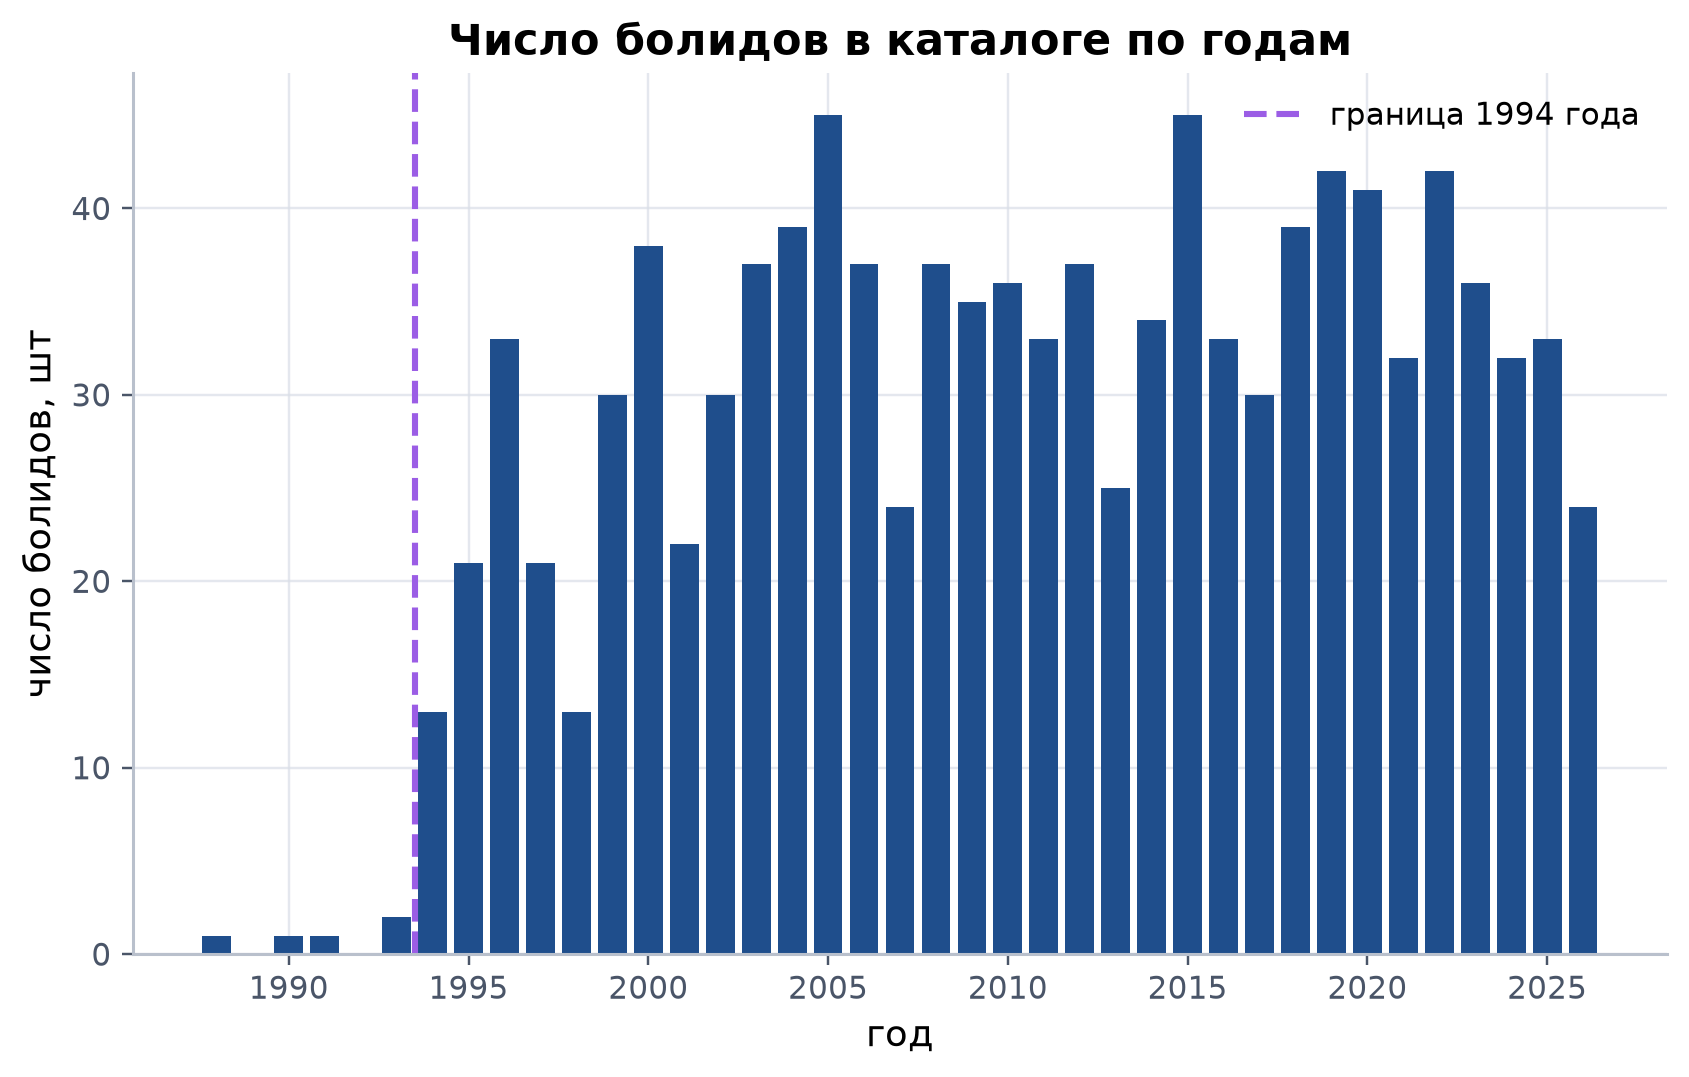

In [8]:
# число болидов в каталоге по годам
per_year = df["date"].dt.year.value_counts().sort_index()

plt.bar(per_year.index, per_year.values, color=C_DATA)
plt.axvline(1993.5, color=C_ACCENT, linestyle="--", label="граница 1994 года")
plt.title("Число болидов в каталоге по годам")
plt.xlabel("год")
plt.ylabel("число болидов, шт")
plt.legend()
plt.show()

In [9]:
# те же числа таблицей: первые годы каталога
print(per_year.head(8))

# и разброс по полным годам с 1994 по 2025
full_years = per_year.loc[1994:2025]
print("с 1994 по 2025 в год: от", full_years.min(), "до", full_years.max(), "болидов")

date
1988     1
1990     1
1991     1
1993     2
1994    13
1995    21
1996    33
1997    21
Name: count, dtype: int64
с 1994 по 2025 в год: от 13 до 45 болидов


На графике видно, что до 1994 каталог практически пуст. А вот с 1994 у нас каждый год от 13 до 45 болидов. Скорее всего в первые годы вспышки просто плохо записывали, NASA сама указывает, что список неполный. Если бы мы оставили годы до 1994 то промежутки там будут аномально большими. Поэтому мы берем данные с 1994 года.

In [10]:
# оставляем болиды с 1994 года
df = df[df["date"] >= "1994-01-01"].reset_index(drop=True)
print("болидов осталось:", len(df))
print("период:", df["date"].min(), "-", df["date"].max())

болидов осталось: 1069
период: 1994-02-01 22:38:09 - 2026-10-04 03:14:45


## Random Variable 01 (интервал между соседними болидами, дни)

### Description

In [11]:
# интервал = сколько дней прошло от предыдущего болида до этого
df["gap_days"] = df["date"].diff().dt.total_seconds() / 86400
df[["date", "gap_days"]].head()

,date,gap_days
0,1994-02-01 22:38:09,NaN
1,1994-05-29 09:30:58,116.453345
2,1994-06-03 20:48:42,5.470648
3,1994-06-15 00:02:27,11.134549
4,1994-08-15 23:16:48,61.968299


In [12]:
# у самого первого болида предыдущего нет, поэтому там пропуск, убираем его
gaps = df["gap_days"].dropna().reset_index(drop=True)

print("интервалов:", len(gaps))
print("самый короткий, дней:", round(gaps.min(), 3))
print("самый длинный, дней:", round(gaps.max(), 1))
print("средний, дней:", round(gaps.mean(), 2))

интервалов: 1068
самый короткий, дней: 0.006
самый длинный, дней: 126.2
средний, дней: 11.17


Первая величина это интервал между соседними болидами в днях. Мы отсортировали болиды по дате и посчитали сколько дней прошло между соседними болидами. Интервал не может быть отрицательным, зато может быть дробным, потому что время записано с точностью до секунды. Всего получилось 1068 интервалов. Самый короткий 0.006 дня, это менее десяти минут, а самый длинный 126 дней. В среднем между болидами проходит около 11 дней.

#### Случайная ли это величина

Проверяем тремя способами: смотрим на интервалы по порядку, сравниваем каждый интервал с предыдущим и с другими столбцами таблицы.

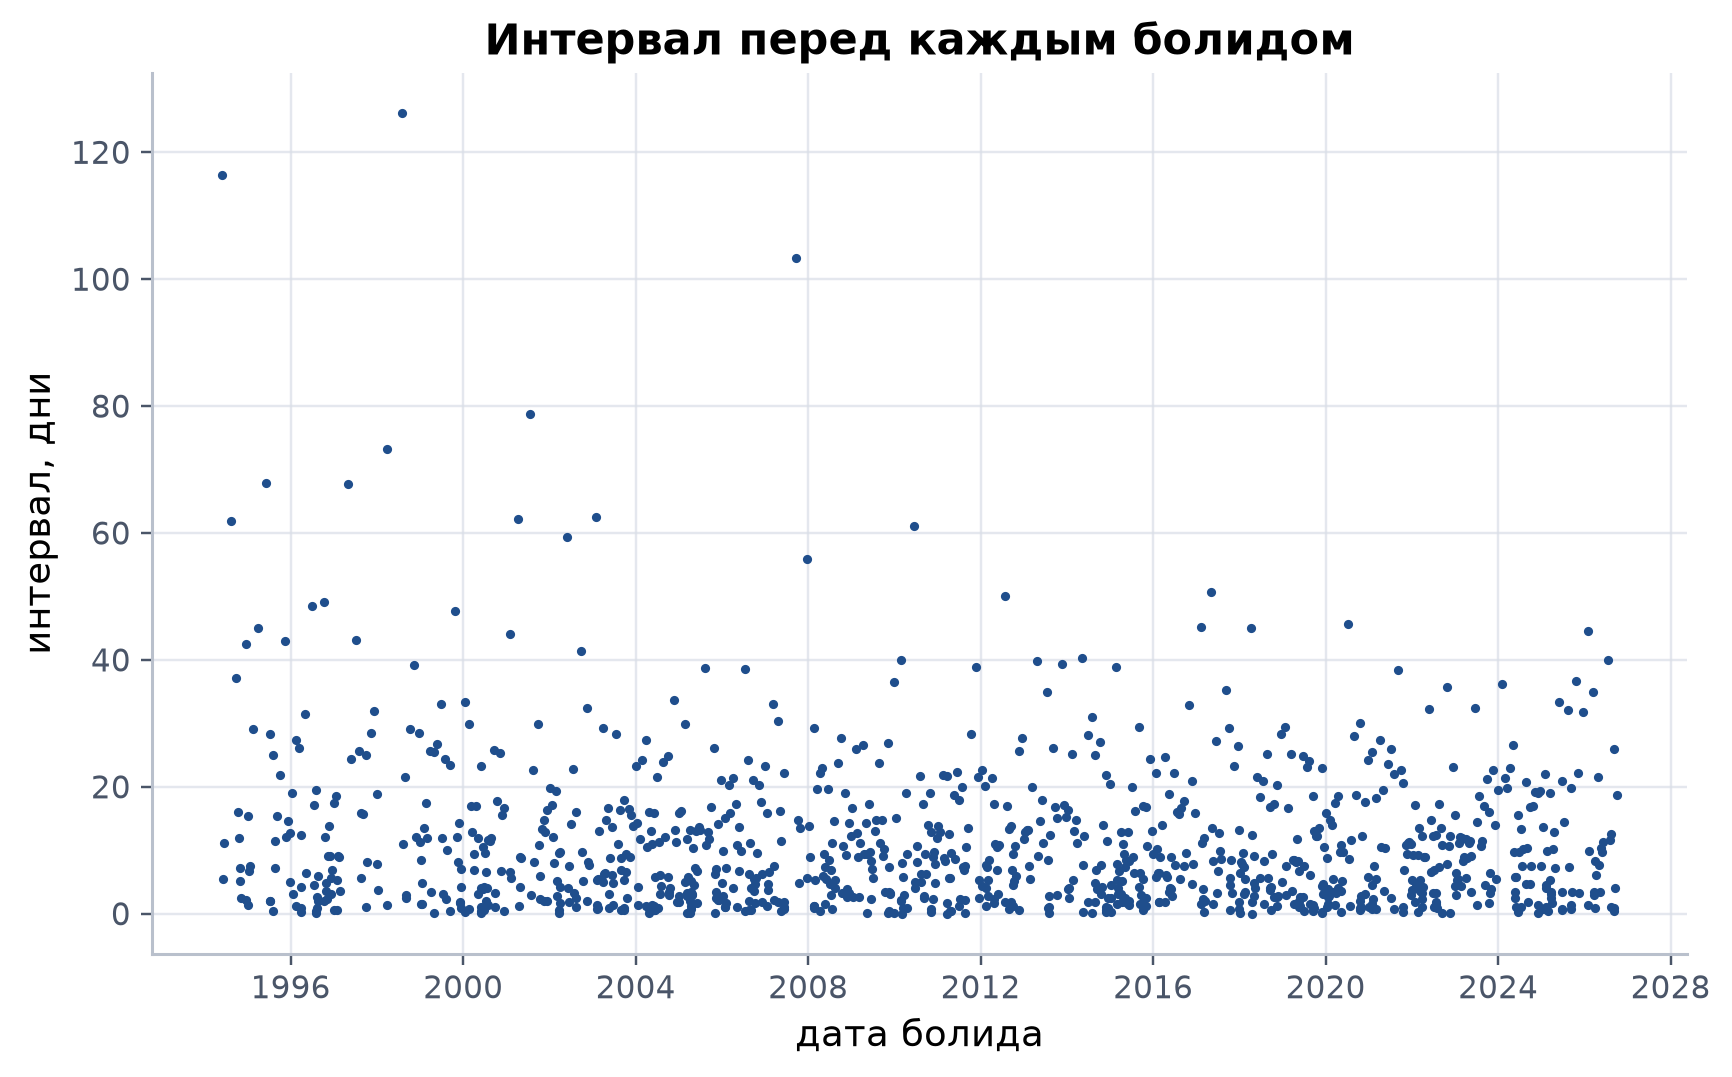

корреляция Спирмена с номером по порядку: -0.041  p-value: 0.182


In [13]:
# 1. интервалы в том порядке, как они шли во времени
plt.plot(df["date"][1:], gaps, ".", color=C_DATA, markersize=4)
plt.title("Интервал перед каждым болидом")
plt.xlabel("дата болида")
plt.ylabel("интервал, дни")
plt.show()

# меняются ли интервалы со временем: корреляция интервала с его номером по порядку
r, p = stats.spearmanr(np.arange(len(gaps)), gaps)
print("корреляция Спирмена с номером по порядку:", round(r, 3), " p-value:", round(p, 3))

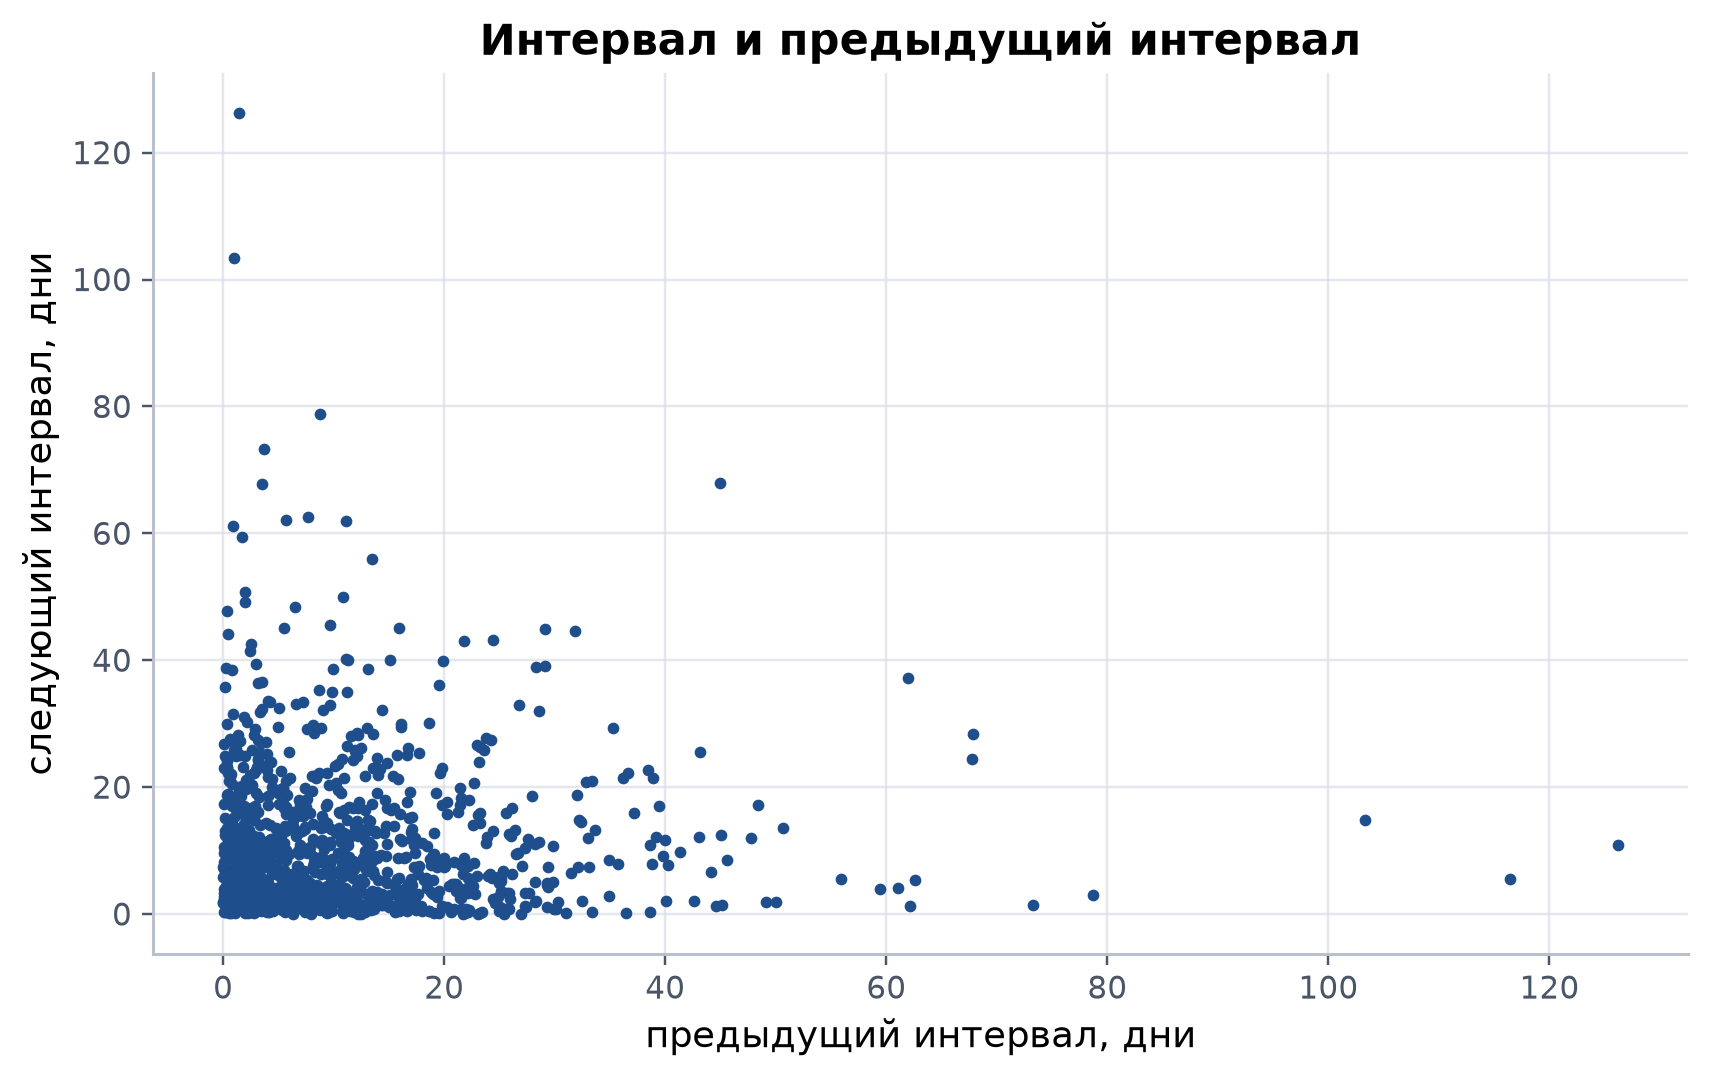

корреляция Спирмена с предыдущим интервалом: -0.006  p-value: 0.854


In [14]:
# 2. можно ли угадать интервал по предыдущему
prev_gap = gaps[:-1].values
next_gap = gaps[1:].values

plt.scatter(prev_gap, next_gap, s=8, color=C_DATA)
plt.title("Интервал и предыдущий интервал")
plt.xlabel("предыдущий интервал, дни")
plt.ylabel("следующий интервал, дни")
plt.show()

r, p = stats.spearmanr(prev_gap, next_gap)
print("корреляция Спирмена с предыдущим интервалом:", round(r, 3), " p-value:", round(p, 3))

In [15]:
# 3. можно ли вычислить интервал по другим столбцам
# считаем корреляцию Спирмена интервала с каждым столбцом
for col in ["energy_kt", "alt_km", "vel_kms", "lat"]:
    pair = df[["gap_days", col]].dropna()
    r, p = stats.spearmanr(pair["gap_days"], pair[col])
    print(col, " корреляция:", round(r, 3), " p-value:", round(p, 3), " пар значений:", len(pair))

energy_kt  корреляция: 0.025  p-value: 0.419  пар значений: 1068
alt_km  корреляция: 0.011  p-value: 0.78  пар значений: 602
vel_kms  корреляция: -0.043  p-value: 0.41  пар значений: 363
lat  корреляция: 0.026  p-value: 0.432  пар значений: 882


По графику интервалов во времени никакого рисунка не видно, в любом году точки интервалов разбросаны непредсказуемо. Правда до 2004 года длинных интервалов будет побольше, но корреляция с номером по порядку слабая (-0.041, p-value 0.182). На втором графике мы видим облако точек без какой-то формы: после короткого интервала может быть и короткий и длинный. Корреляция с предыдущим интервалом почти ноль (-0.006). По другим столбцам также корреляции около нуля и p-value везде больше 0.4. Значит формулы по которой можно посчитать когда упадет следующий болид не существует, тогда интервал это и есть случайная величина.

### EDA & Distribution

In [16]:
# описательные статистики интервалов
q1 = gaps.quantile(0.25)
q3 = gaps.quantile(0.75)

gap_stats = pd.Series({
    "количество": len(gaps),
    "среднее, дни": gaps.mean(),
    "медиана, дни": gaps.median(),
    "дисперсия, дни^2": gaps.var(),
    "стандартное отклонение, дни": gaps.std(),
    "минимум, дни": gaps.min(),
    "первый квартиль, дни": q1,
    "третий квартиль, дни": q3,
    "максимум, дни": gaps.max(),
    "межквартильный размах, дни": q3 - q1,
    "асимметрия": gaps.skew(),
    "эксцесс": gaps.kurt(),
})
gap_stats.round(3)

количество                     1068.000
среднее, дни                     11.172
медиана, дни                      7.627
дисперсия, дни^2                153.069
стандартное отклонение, дни      12.372
минимум, дни                      0.006
первый квартиль, дни              2.906
третий квартиль, дни             15.428
максимум, дни                   126.214
межквартильный размах, дни       12.522
асимметрия                        3.099
эксцесс                          17.325
dtype: float64

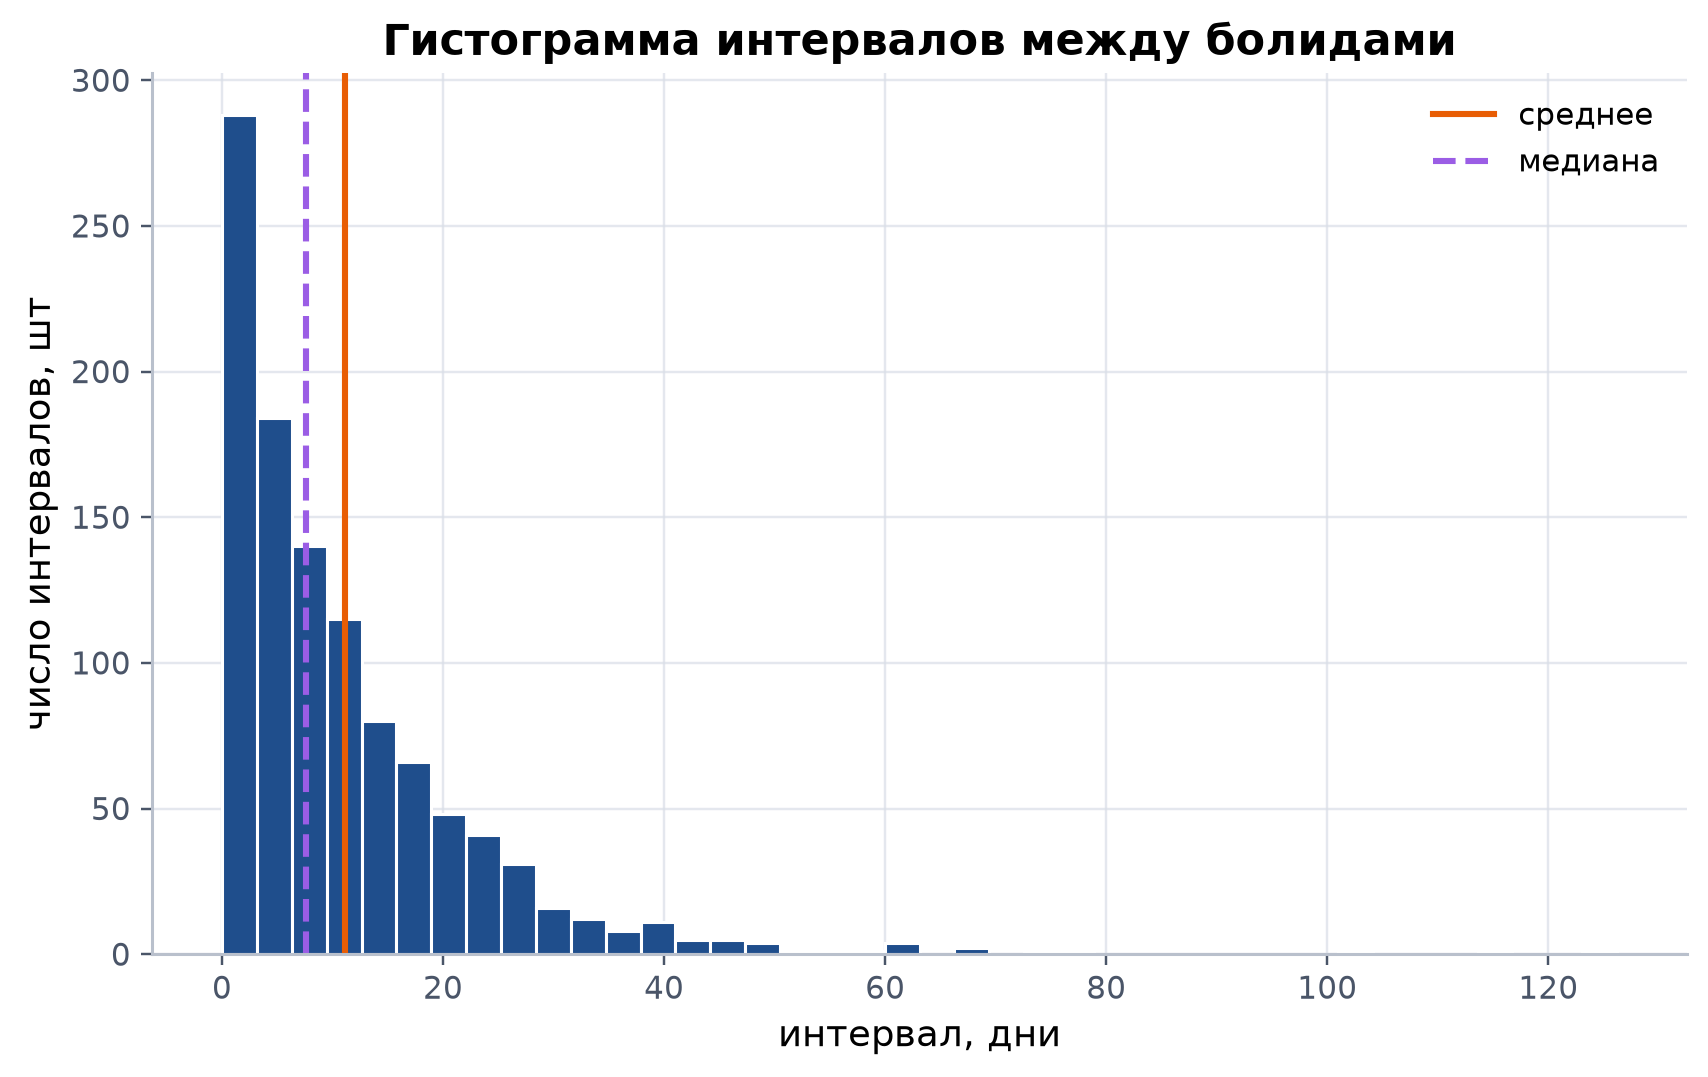

In [17]:
# гистограмма интервалов, отмечаем среднее и медиану
plt.hist(gaps, bins=40, color=C_DATA, edgecolor="white")
plt.axvline(gaps.mean(), color=C_THEORY, label="среднее")
plt.axvline(gaps.median(), color=C_ACCENT, linestyle="--", label="медиана")
plt.title("Гистограмма интервалов между болидами")
plt.xlabel("интервал, дни")
plt.ylabel("число интервалов, шт")
plt.legend()
plt.show()

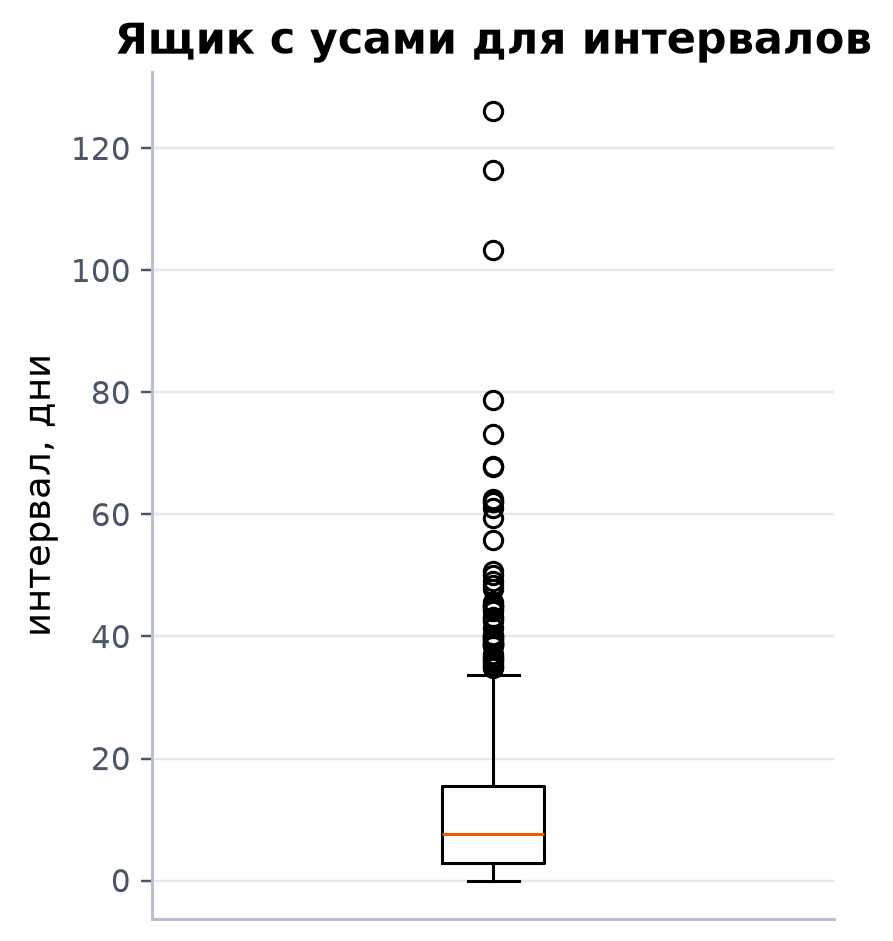

In [18]:
# ящик с усами
plt.figure(figsize=(4, 5))
plt.boxplot(gaps)
plt.title("Ящик с усами для интервалов")
plt.ylabel("интервал, дни")
plt.xticks([])
plt.show()

In [19]:
# выбросы по правилу полутора межквартильных размахов
upper = q3 + 1.5 * (q3 - q1)
print("верхняя граница, дни:", round(upper, 2))
print("интервалов больше границы:", (gaps > upper).sum(), "из", len(gaps))

# пять самых длинных интервалов и даты болидов перед которыми они были
df.nlargest(5, "gap_days")[["date", "gap_days"]]

верхняя граница, дни: 34.21
интервалов больше границы: 47 из 1068


,date,gap_days
92,1998-07-28 14:16:53,126.214340
1,1994-05-29 09:30:58,116.453345
397,2007-09-22 17:57:13,103.340370
177,2001-07-23 22:19:11,78.742153
90,1998-03-22 22:25:37,73.260602


По гистограмме видно что больше всего коротких интервалов, самый высокий столбик у нуля, а дальше они постепенно убывают. Половина интервалов короче 7.6 дня, три четверти короче 15.4. При этом среднее 11.2 дня, оно больше медианы потому что у нас есть редкие длинные интервалы и они тянут среднее вверх. Асимметрия 3.1, то есть хвост справа длинный получается. По правилу полутора размахов выбросами считаются интервалы длиннее 34.2 дня, таких 47 из 1068. Самый длинный интервал 126 дней, он перед болидом в июле 1998. Мы их не выкидываем, ведь это не ошибки в данных, просто иногда бывает так, что болидов долго нет.

#### Нормализация

Формулы двух способов:

$$x_{minmax} = \frac{x - x_{min}}{x_{max} - x_{min}}, \qquad z = \frac{x - \bar{x}}{s}$$

где $x$ интервал, $x_{min}$ и $x_{max}$ самый короткий и самый длинный интервал, $\bar{x}$ среднее, $s$ стандартное отклонение.

In [20]:
# приводим интервалы к другому масштабу двумя способами
gaps_minmax = (gaps - gaps.min()) / (gaps.max() - gaps.min())   # все значения от 0 до 1
gaps_z = (gaps - gaps.mean()) / gaps.std()                      # среднее 0, стандартное отклонение 1

norm_table = pd.DataFrame({"исходные, дни": gaps, "min-max": gaps_minmax, "z-оценка": gaps_z})
norm_table.describe().round(3)

,"исходные, дни",min-max,z-оценка
count,1068.000,1068.000,1068.000
mean,11.172,0.088,-0.000
std,12.372,0.098,1.000
min,0.006,0.000,-0.903
25%,2.906,0.023,-0.668
50%,7.627,0.060,-0.287
75%,15.428,0.122,0.344
max,126.214,1.000,9.298


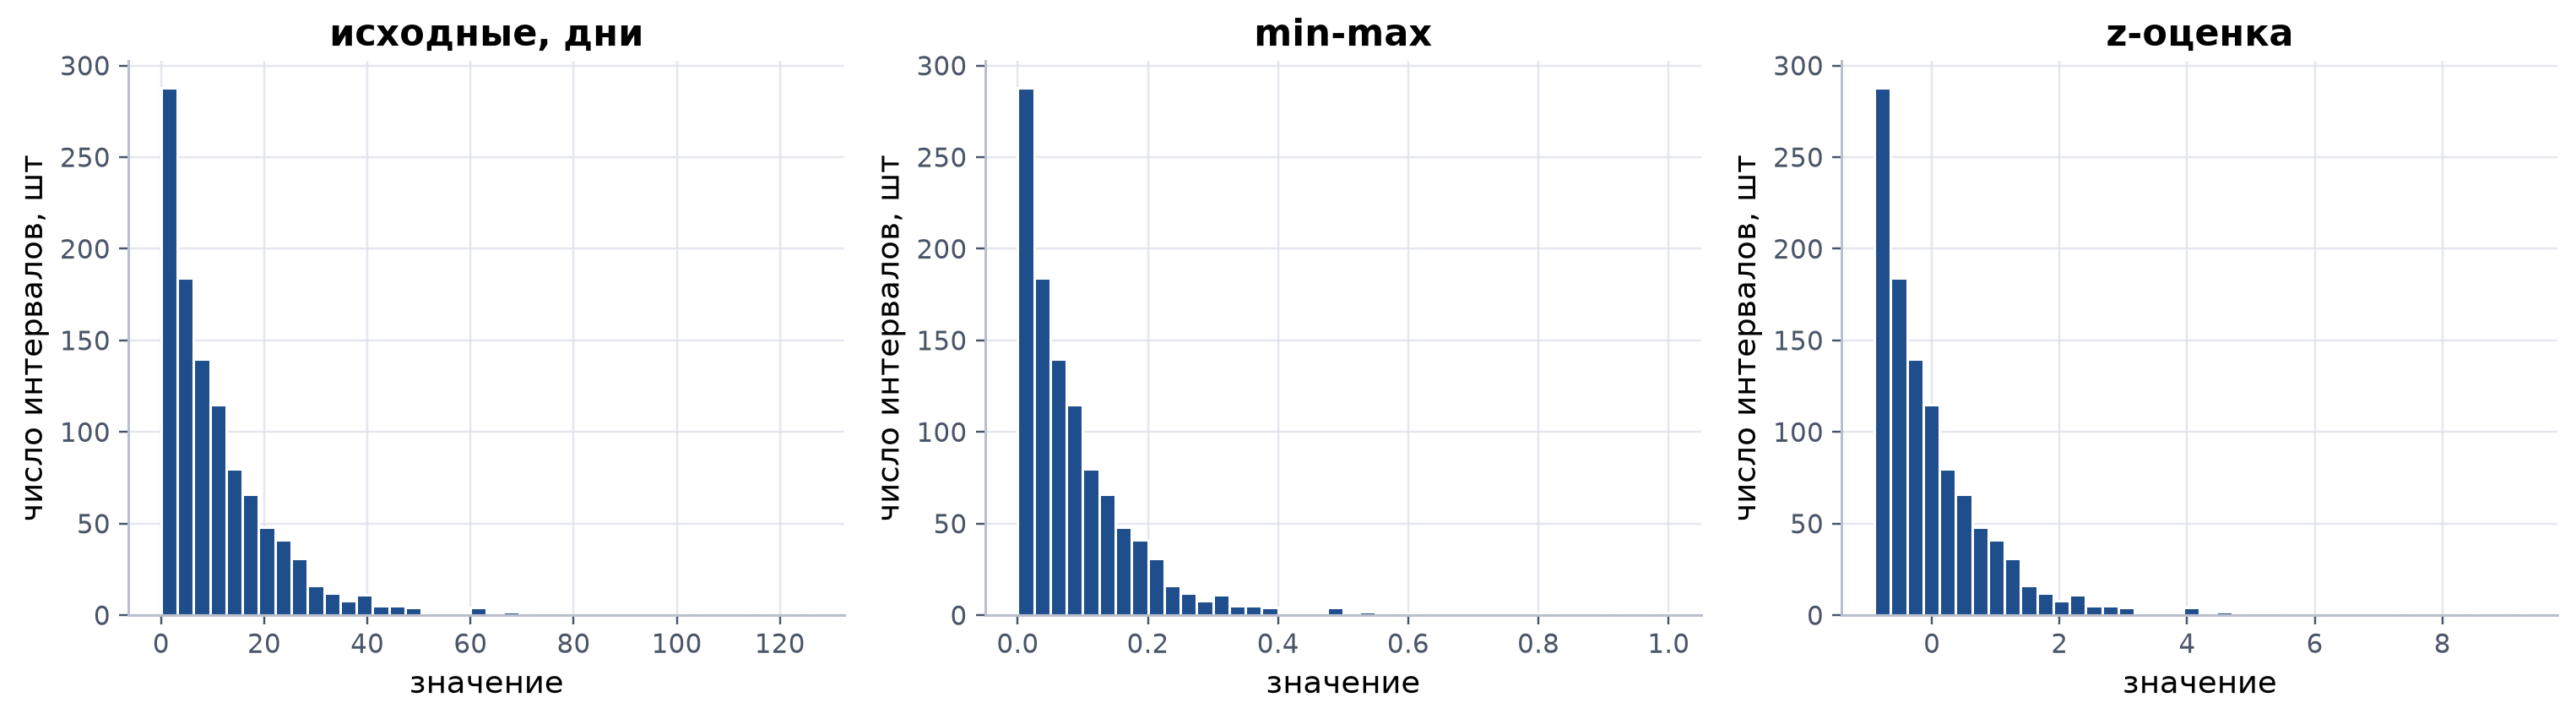

асимметрия: {'исходные, дни': 3.099, 'min-max': 3.099, 'z-оценка': 3.099}


In [21]:
# три гистограммы рядом: меняется только шкала, форма та же
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, norm_table.columns):
    ax.hist(norm_table[col], bins=40, color=C_DATA, edgecolor="white")
    ax.set_title(col)
    ax.set_xlabel("значение")
    ax.set_ylabel("число интервалов, шт")
plt.tight_layout()
plt.show()

print("асимметрия:", norm_table.skew().round(3).to_dict())

Min-max переводит все значения в отрезок от 0 до 1: самый короткий интервал становится нулем, а самый длинный единицей. Z-оценка же показывает на сколько стандартных отклонений значение отличается от среднего, после нее среднее равно 0 а отклонение 1. Это нужно чтобы сравнивать величины в разных единицах, например дни и штуки. По трем гистограммам видно что форма не поменялась, поменялись только числа на оси. Асимметрия тоже осталась 3.099 во всех трех случаях. То есть нормализация не делает распределение нормальным, она только меняет масштаб принимаемых значений.

#### Распределение

По гистограмме интервалы похожи на экспоненциальное распределение. Его формулы:

$$f(x) = \lambda e^{-\lambda x}, \quad x \ge 0 \qquad\qquad F(x) = 1 - e^{-\lambda x}$$

$$E[X] = \frac{1}{\lambda}, \qquad D[X] = \frac{1}{\lambda^2}, \qquad \sigma = \frac{1}{\lambda}, \qquad Me = \frac{\ln 2}{\lambda}$$

Свойство отсутствия памяти:

$$P(X > s + t \mid X > s) = P(X > t)$$

Здесь $f(x)$ плотность, $F(x)$ функция распределения, $\lambda$ параметр (среднее число событий в день), $E[X]$ математическое ожидание, $D[X]$ дисперсия, $\sigma$ стандартное отклонение, $Me$ медиана. Асимметрия у экспоненциального распределения всегда равна 2.

лямбда, болидов в день: 0.0895


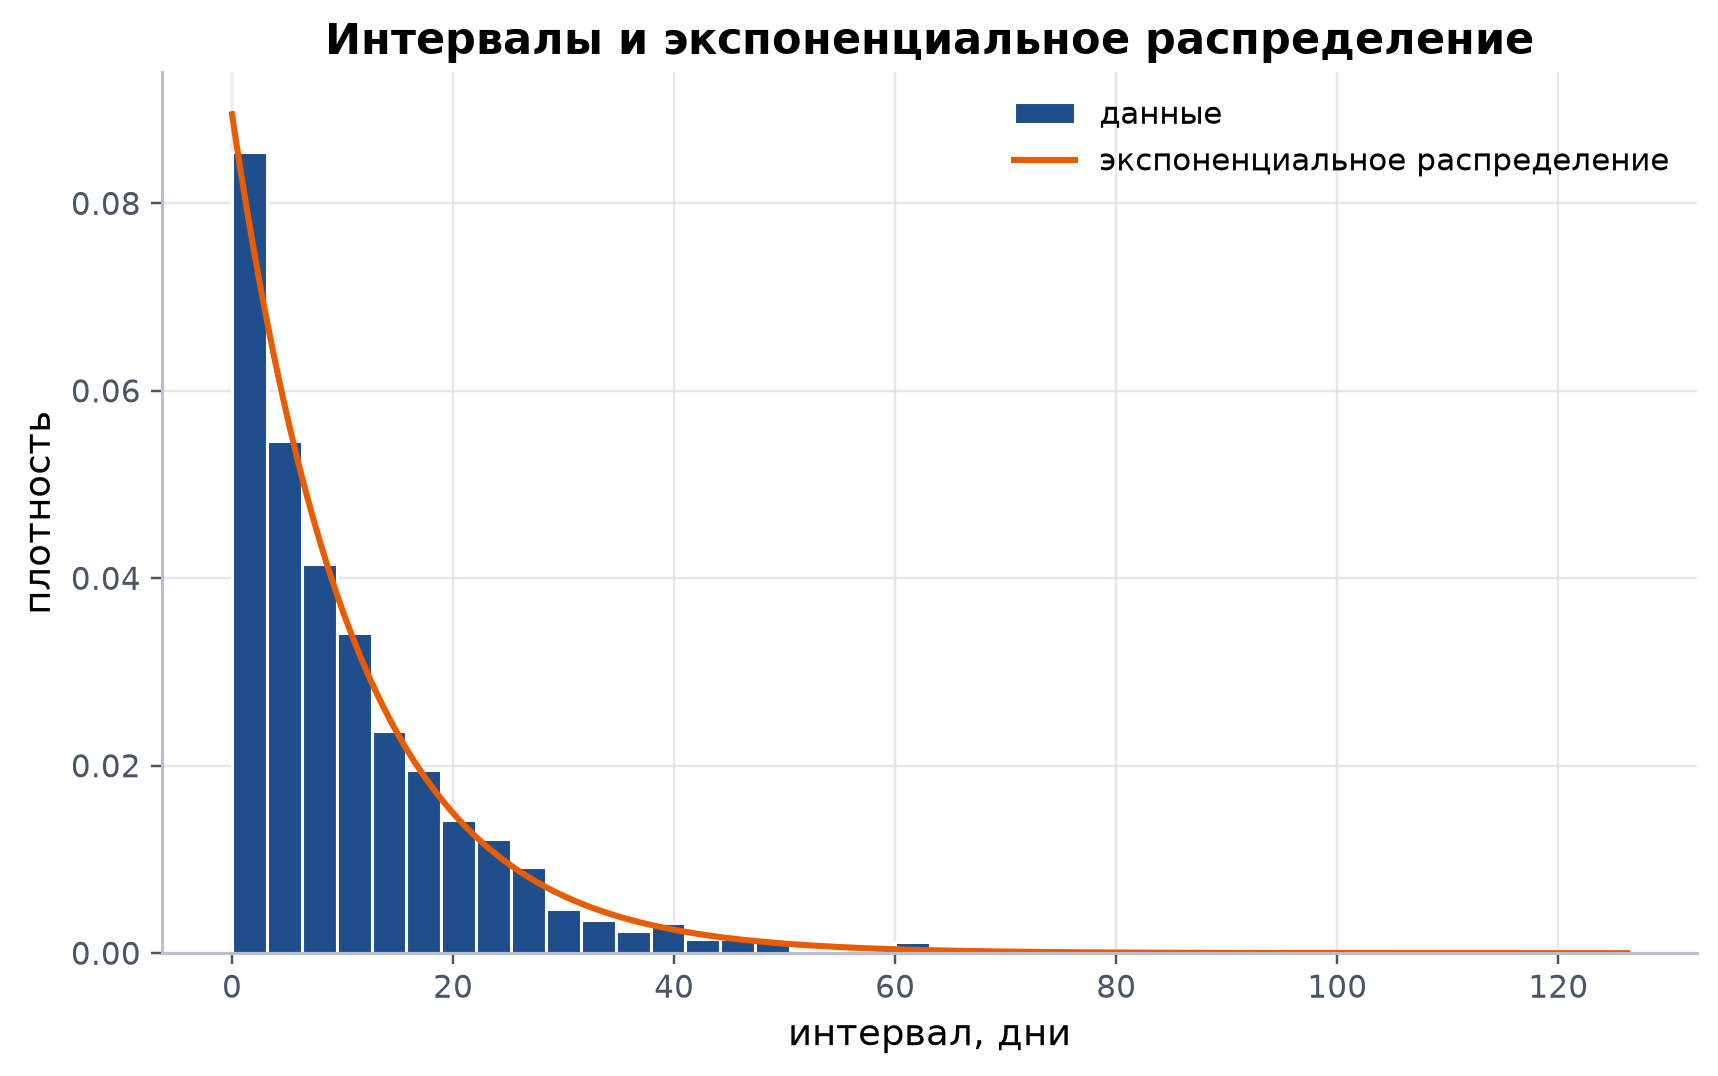

In [22]:
# параметр лямбда оцениваем по данным: это единица делить на среднее
lam = 1 / gaps.mean()
print("лямбда, болидов в день:", round(lam, 4))

# гистограмма в виде плотности и поверх теоретическая кривая
x = np.linspace(0, gaps.max(), 300)
plt.hist(gaps, bins=40, density=True, color=C_DATA, edgecolor="white", label="данные")
plt.plot(x, lam * np.exp(-lam * x), color=C_THEORY, linewidth=2, label="экспоненциальное распределение")
plt.title("Интервалы и экспоненциальное распределение")
plt.xlabel("интервал, дни")
plt.ylabel("плотность")
plt.legend()
plt.show()

In [23]:
# сравниваем числа из данных с тем что должно быть по формулам
compare = pd.DataFrame({
    "по данным": [gaps.mean(), gaps.std(), gaps.median(), gaps.skew()],
    "по формулам": [1 / lam, 1 / lam, np.log(2) / lam, 2],
}, index=["среднее, дни", "стандартное отклонение, дни", "медиана, дни", "асимметрия"])
compare.round(3)

,по данным,по формулам
"среднее, дни",11.172,11.172
"стандартное отклонение, дни",12.372,11.172
"медиана, дни",7.627,7.744
асимметрия,3.099,2.000


Экспоненциальное распределение описывает время ожидания события, если события случаются независимо друг от друга и в среднем с одной частотой. Болиды как раз такие: камни летят сами по себе и один никак не влияет на другой. Отсутствие памяти означает что если болида не было уже месяц, то шанс что он будет завтра такой же как обычно. Оранжевая кривая отлично легла на гистограмму. В таблице медиана почти совпала (7.627 и 7.744), а стандартное отклонение у нас чуть больше чем по формуле (12.372 против 11.172) и асимметрия тоже больше (3.099 против 2). Так получилось из-за нескольких очень длинных интервалов.

#### Проверка гипотезы

$H_0$: интервалы распределены экспоненциально с параметром $\lambda$.

$H_1$: распределение другое.

Уровень значимости $\alpha = 0.05$. Проверяем критерием Колмогорова-Смирнова.

статистика D: 0.0333
p-value: 0.184


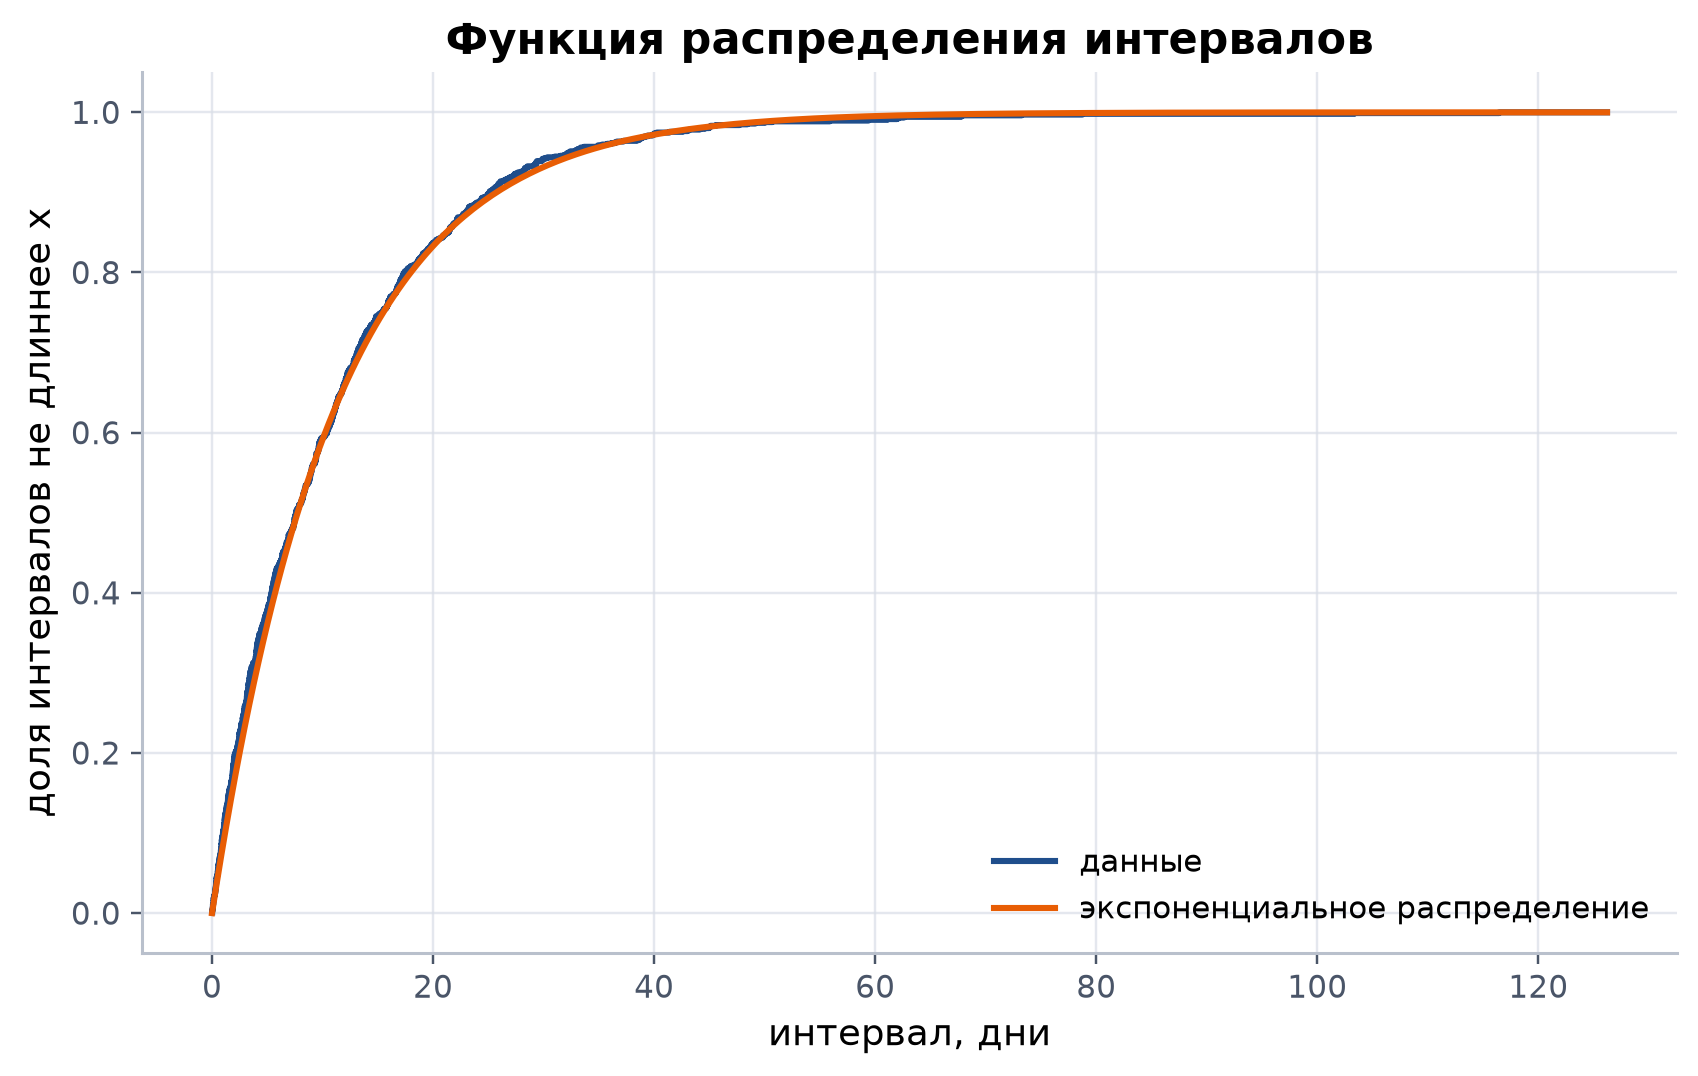

In [24]:
# критерий Колмогорова-Смирнова: сравнивает функцию распределения данных с теоретической
# args=(0, 1/lam): сдвиг 0 и масштаб 1/лямбда
D, p_value = stats.kstest(gaps, "expon", args=(0, 1 / lam))
print("статистика D:", round(D, 4))
print("p-value:", round(p_value, 3))

# эмпирическая и теоретическая функции распределения на одном графике
sorted_gaps = np.sort(gaps)
plt.step(sorted_gaps, np.arange(1, len(gaps) + 1) / len(gaps), color=C_DATA, label="данные")
plt.plot(x, 1 - np.exp(-lam * x), color=C_THEORY, label="экспоненциальное распределение")
plt.title("Функция распределения интервалов")
plt.xlabel("интервал, дни")
plt.ylabel("доля интервалов не длиннее x")
plt.legend()
plt.show()

Проверяли мы что интервалы распределены экспоненциально. Статистика D означает самое большое расстояние между двумя линиями на графике, у нас 0.0333, то есть линии нигде не расходятся больше чем на 3.3%. P-value получилось 0.184, это больше 0.05, значит гипотезу не отвергаем. Правда параметр лямбда мы посчитали по этим же данным, из-за этого p-value может быть немного завышено. Но в целом данные не противоречат тому что болиды падают как случайный поток независимых событий.

### Independence & Estimations

Зависимость интервалов от числа болидов за месяц проверяем в разделе второй величины, там будут обе.

#### Выборка и генеральная совокупность

Генеральная совокупность это все 1068 интервалов. Берем из них случайную выборку из 200 двумя способами: без возвращения (каждый интервал можно взять только один раз) и с возвращением (один и тот же интервал может попасться несколько раз).

In [25]:
n = 200

sample_without = gaps.sample(n, replace=False, random_state=1)
sample_with = gaps.sample(n, replace=True, random_state=1)

print("повторов в выборке без возвращения:", n - sample_without.index.nunique())
print("повторов в выборке с возвращением:", n - sample_with.index.nunique())

sample_table = pd.DataFrame({
    "все 1068 интервалов": [gaps.mean(), gaps.median(), gaps.std()],
    "выборка без возвращения": [sample_without.mean(), sample_without.median(), sample_without.std()],
    "выборка с возвращением": [sample_with.mean(), sample_with.median(), sample_with.std()],
}, index=["среднее, дни", "медиана, дни", "стандартное отклонение, дни"])
sample_table.round(3)

повторов в выборке без возвращения: 0
повторов в выборке с возвращением: 20


,все 1068 интервалов,выборка без возвращения,выборка с возвращением
"среднее, дни",11.172,11.366,11.480
"медиана, дни",7.627,7.563,7.677
"стандартное отклонение, дни",12.372,13.148,11.626


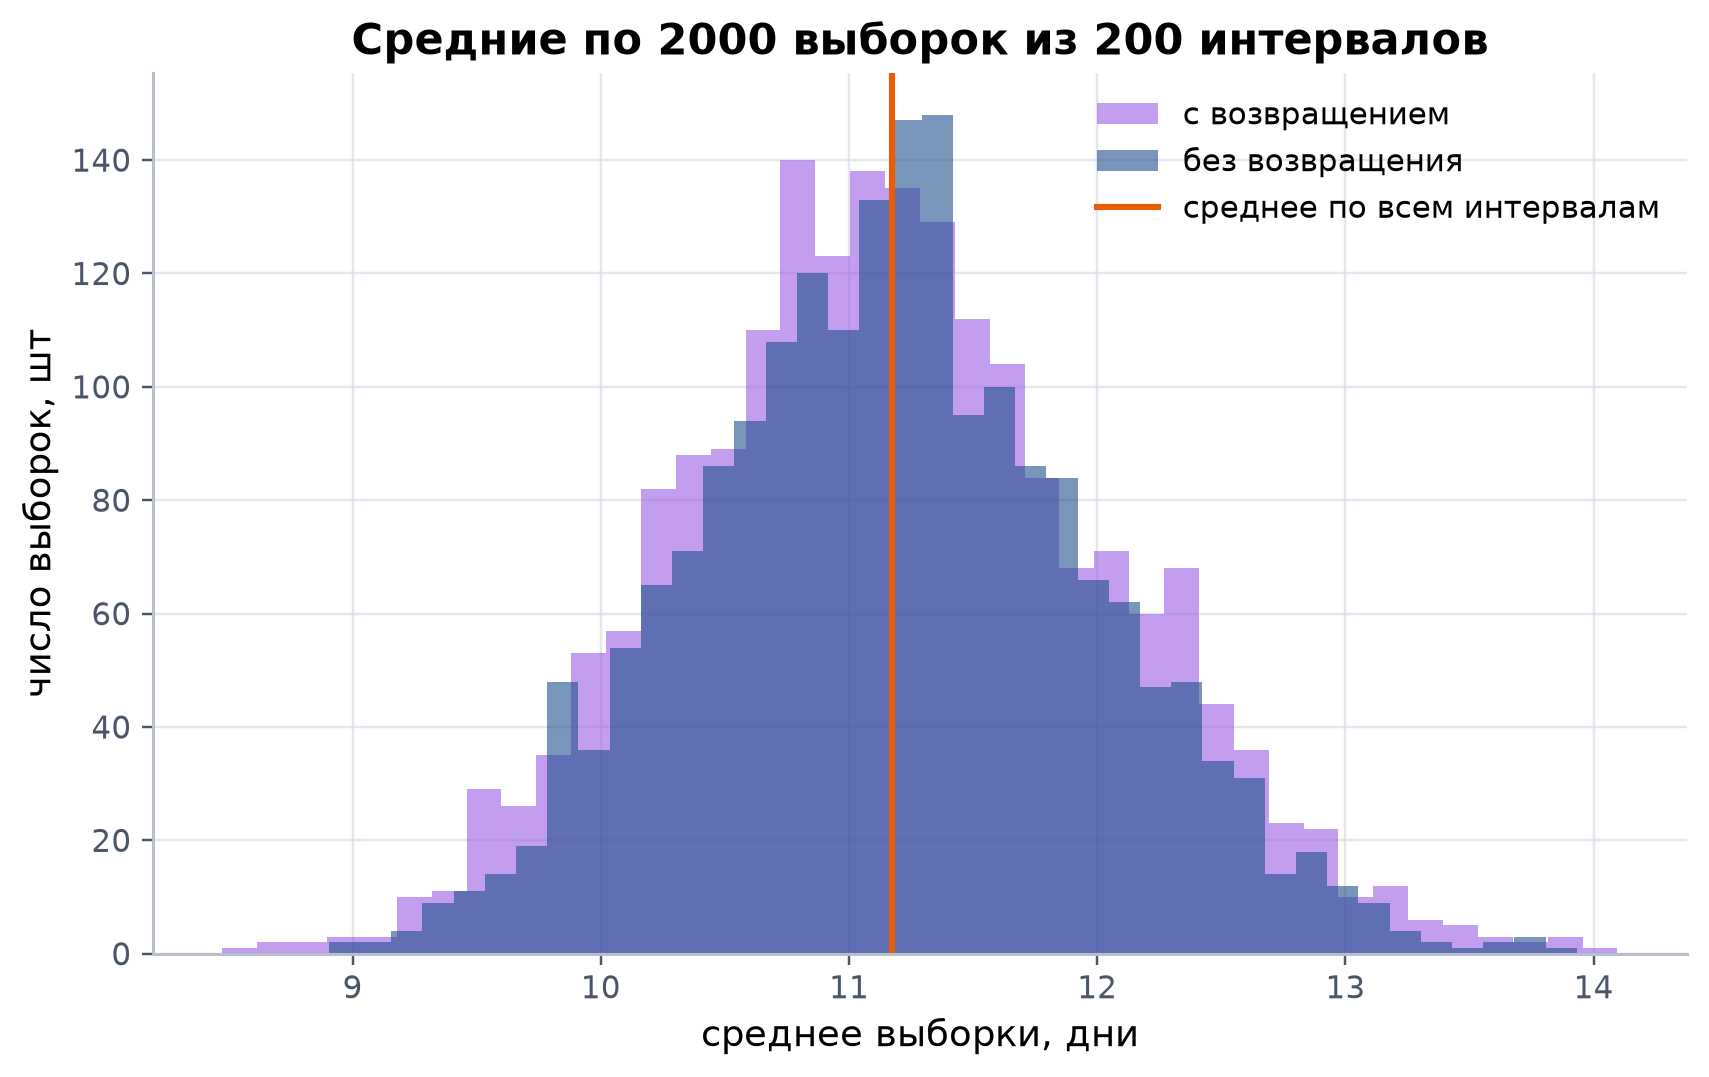

среднее по всем интервалам: 11.172
без возвращения: среднее средних 11.185  разброс (ст. отклонение) 0.793
с возвращением:  среднее средних 11.179  разброс (ст. отклонение) 0.864


In [26]:
# одна выборка может случайно получиться удачной или неудачной
# поэтому берем по 2000 выборок каждым способом и смотрим как разбросаны их средние
means_without = [gaps.sample(n, replace=False, random_state=i).mean() for i in range(2000)]
means_with = [gaps.sample(n, replace=True, random_state=i).mean() for i in range(2000)]

plt.hist(means_with, bins=40, alpha=0.6, color=C_ACCENT, label="с возвращением")
plt.hist(means_without, bins=40, alpha=0.6, color=C_DATA, label="без возвращения")
plt.axvline(gaps.mean(), color=C_THEORY, label="среднее по всем интервалам")
plt.title("Средние по 2000 выборок из 200 интервалов")
plt.xlabel("среднее выборки, дни")
plt.ylabel("число выборок, шт")
plt.legend()
plt.show()

print("среднее по всем интервалам:", round(gaps.mean(), 3))
print("без возвращения: среднее средних", round(np.mean(means_without), 3), " разброс (ст. отклонение)", round(np.std(means_without), 3))
print("с возвращением:  среднее средних", round(np.mean(means_with), 3), " разброс (ст. отклонение)", round(np.std(means_with), 3))

Без возвращения каждый интервал можно взять один раз, с возвращением один и тот же может попасться несколько раз, у нас так получилось 20 повторов из 200. По таблице обе выборки похожи на все данные: среднее 11.4 и 11.5 против 11.2. Но одна выборка могла просто удачно получиться, поэтому мы взяли по 2000 выборок. Их средние лежат вокруг 11.17, то есть вокруг настоящего среднего. У выборок без возвращения разброс меньше (0.793 против 0.864), потому что в них нет повторов и попадает больше разных значений. Значит по выборке из 200 интервалов можно судить о всех, т.к. ошибка среднего меньше одного дня.

#### Состоятельность оценок

Оценка состоятельная, если при росте числа наблюдений она приближается к настоящему значению. Проверяем на среднем и на стандартном отклонении: перемешиваем интервалы и считаем оценку по первым 2, 3, 4 и так далее значениям.

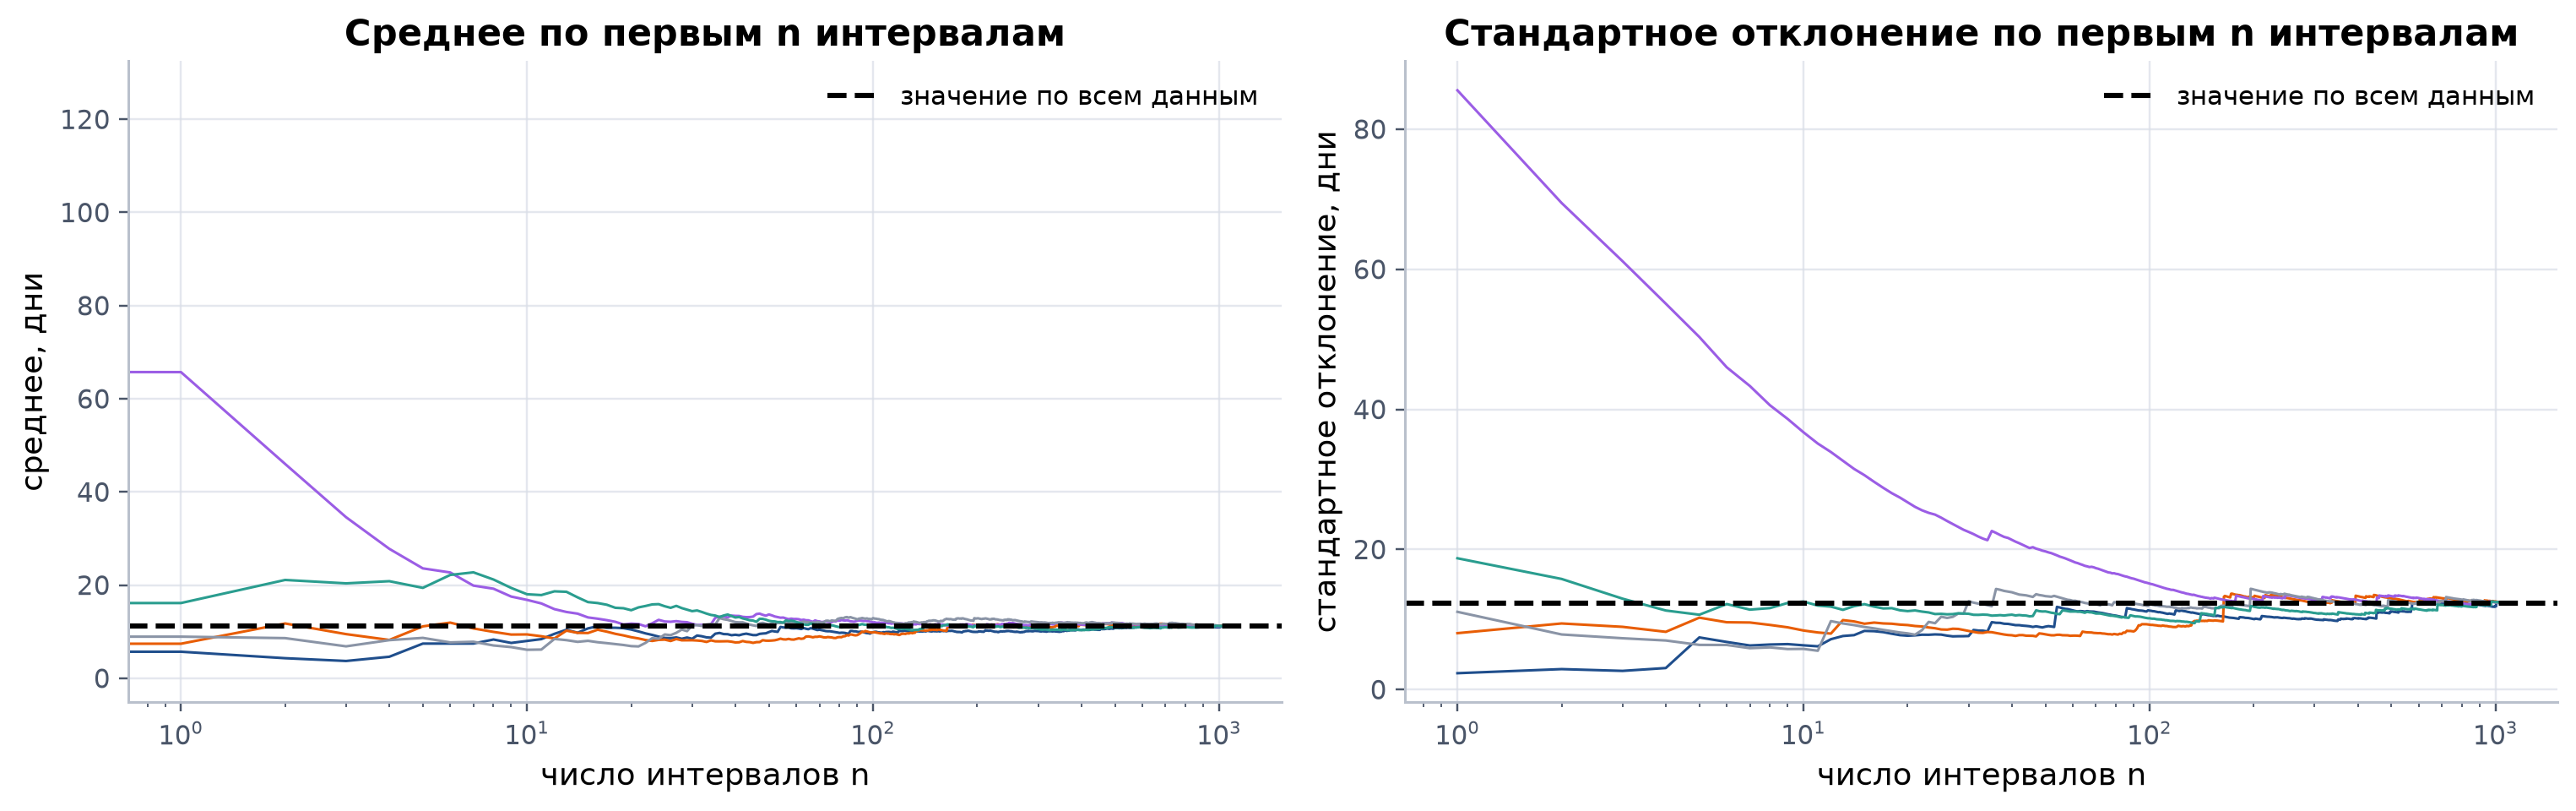

n = 10  среднее: 7.59  ст. отклонение: 6.49
n = 50  среднее: 9.65  ст. отклонение: 8.87
n = 200  среднее: 9.96  ст. отклонение: 10.09
n = 500  среднее: 10.8  ст. отклонение: 11.15
n = 1068  среднее: 11.17  ст. отклонение: 12.37


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# пять разных перемешиваний, чтобы было видно что дело не в одном удачном порядке
for seed in range(5):
    shuffled = gaps.sample(frac=1, random_state=seed).reset_index(drop=True)
    axes[0].plot(shuffled.expanding().mean(), linewidth=1)
    axes[1].plot(shuffled.expanding().std(), linewidth=1)

axes[0].axhline(gaps.mean(), color="black", linestyle="--", label="значение по всем данным")
axes[0].set_title("Среднее по первым n интервалам")
axes[0].set_ylabel("среднее, дни")
axes[1].axhline(gaps.std(), color="black", linestyle="--", label="значение по всем данным")
axes[1].set_title("Стандартное отклонение по первым n интервалам")
axes[1].set_ylabel("стандартное отклонение, дни")
for ax in axes:
    ax.set_xlabel("число интервалов n")
    ax.set_xscale("log")
    ax.legend()
plt.tight_layout()
plt.show()

# то же числами для одного перемешивания
shuffled = gaps.sample(frac=1, random_state=0).reset_index(drop=True)
for k in [10, 50, 200, 500, 1068]:
    print("n =", k, " среднее:", round(shuffled[:k].mean(), 2), " ст. отклонение:", round(shuffled[:k].std(), 2))

При малом числе интервалов оценки прыгают: в одном из перемешиваний среднее по первым значениям было около 65 дней, потому что первым попался длинный интервал. Чем больше n, тем ближе все пять линий к пунктиру, после ста интервалов линии уже почти не расходятся. По числам тоже видно: среднее идет так: 7.59, 9.65, 9.96, 10.8 и приходит к 11.17. Стандартное отклонение сходится медленнее, ведь на него сильнее влияют редкие длинные интервалы. Вывод: обе оценки состоятельные, с ростом числа наблюдений они приближаются к значению по всем данным.

## Random Variable 02 (число болидов за месяц)

### Description

In [28]:
# считаем сколько болидов было в каждом месяце
# берем только полные месяцы: с февраля 1994 (первая запись 1 февраля 1994)
# по сентябрь 2026 (последняя запись 4 октября 2026, октябрь неполный)
all_months = pd.period_range("1994-02", "2026-09", freq="M")
monthly = df["date"].dt.to_period("M").value_counts().reindex(all_months, fill_value=0).sort_index()

print("месяцев:", len(monthly))
print("болидов в них:", monthly.sum())
print("месяцев без болидов:", (monthly == 0).sum())
print("самое большое число за месяц:", monthly.max())
monthly.head()

месяцев: 392
болидов в них: 1068
месяцев без болидов: 28
самое большое число за месяц: 10


1994-02    1
1994-03    0
1994-04    0
1994-05    1
1994-06    2
Freq: M, Name: count, dtype: int64

Вторая величина это сколько болидов было за месяц. Мы просто посчитали болиды в каждом месяце. Число тут всегда целое и не меньше нуля. Брали только полные месяцы, с февраля 1994 по сентябрь 2026, т.к. октябрь 2026 еще не закончен в каталоге. Получилось 392 месяца. В 28 из них болидов не было вообще, их мы тоже считаем как ноль, иначе среднее будет больше чем на самом деле.

#### Случайная ли это величина

Проверяем тремя способами: меняется ли число с годами, зависит ли от прошлого месяца и зависит ли от времени года.

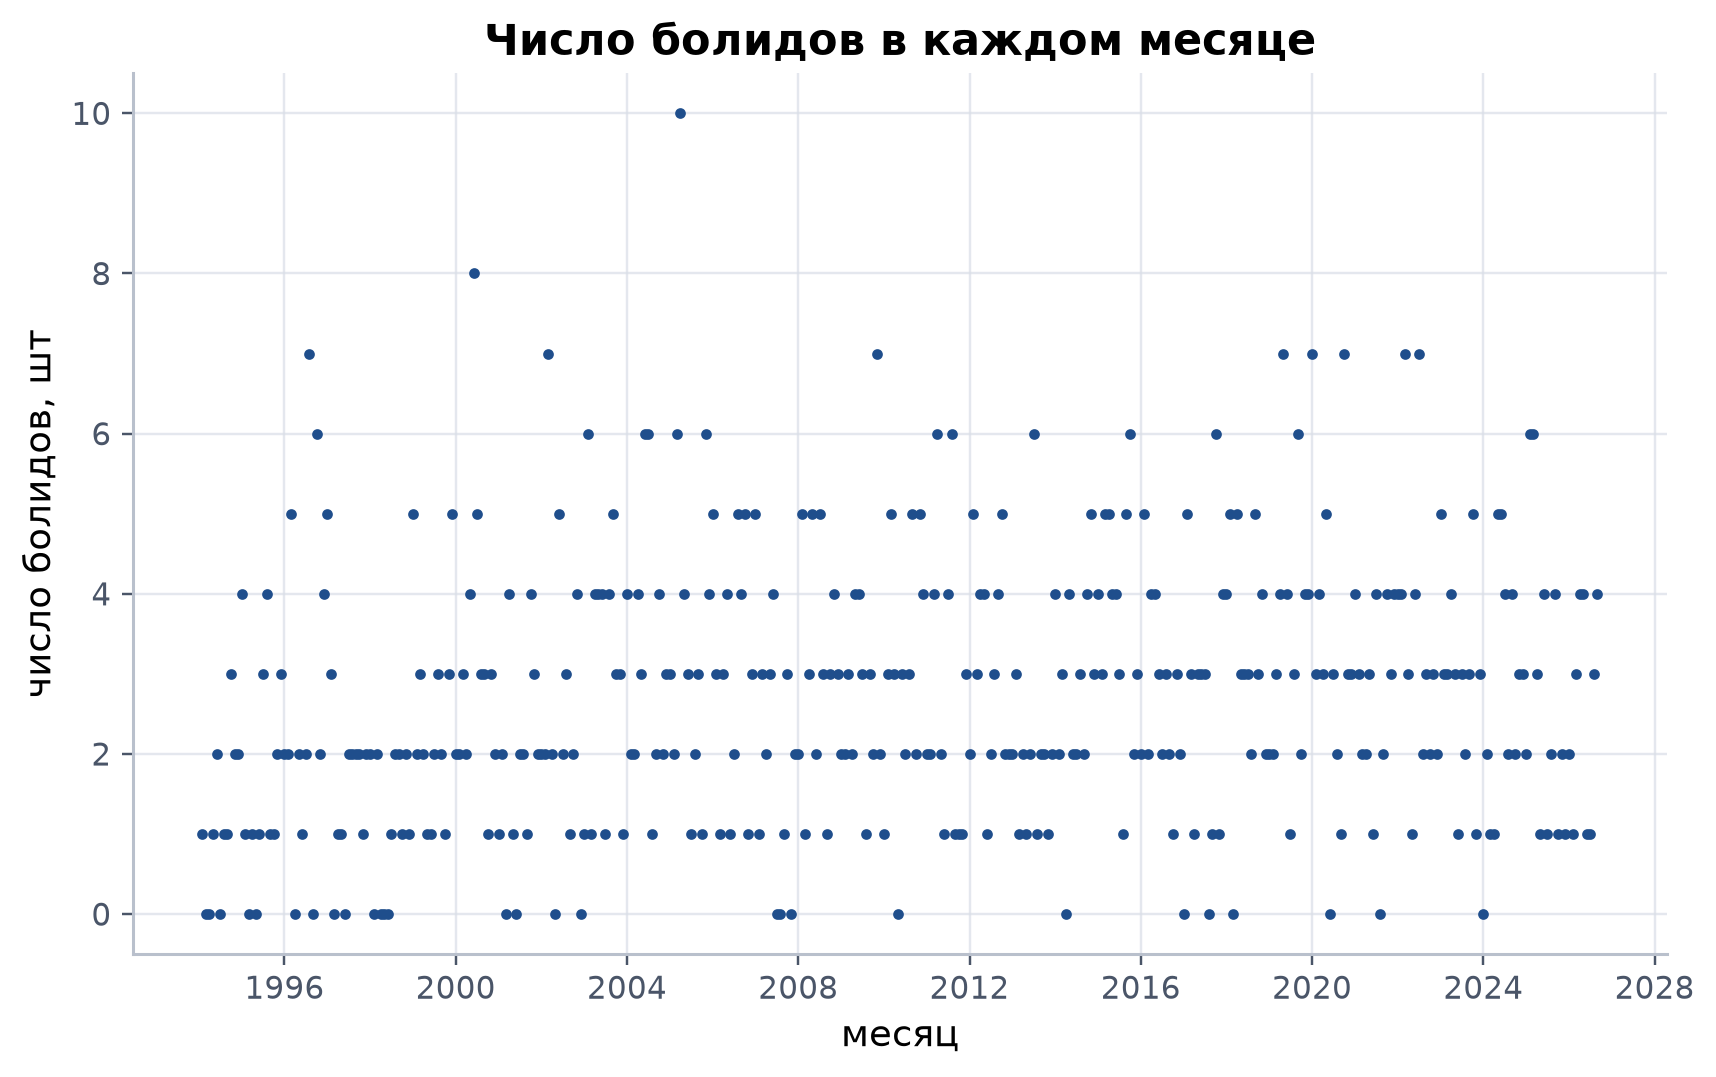

корреляция Спирмена с номером месяца по порядку: 0.213  p-value: 2e-05
среднее за месяц в 1994-1999: 1.85
среднее за месяц в 2000-2026: 2.92


In [29]:
# 1. число болидов по месяцам во времени
plt.plot(monthly.index.to_timestamp(), monthly.values, ".", color=C_DATA, markersize=5)
plt.title("Число болидов в каждом месяце")
plt.xlabel("месяц")
plt.ylabel("число болидов, шт")
plt.show()

r, p = stats.spearmanr(np.arange(len(monthly)), monthly.values)
print("корреляция Спирмена с номером месяца по порядку:", round(r, 3), " p-value:", round(p, 5))

# среднее за месяц в начале каталога и потом
print("среднее за месяц в 1994-1999:", round(monthly[:"1999-12"].mean(), 2))
print("среднее за месяц в 2000-2026:", round(monthly["2000-01":].mean(), 2))

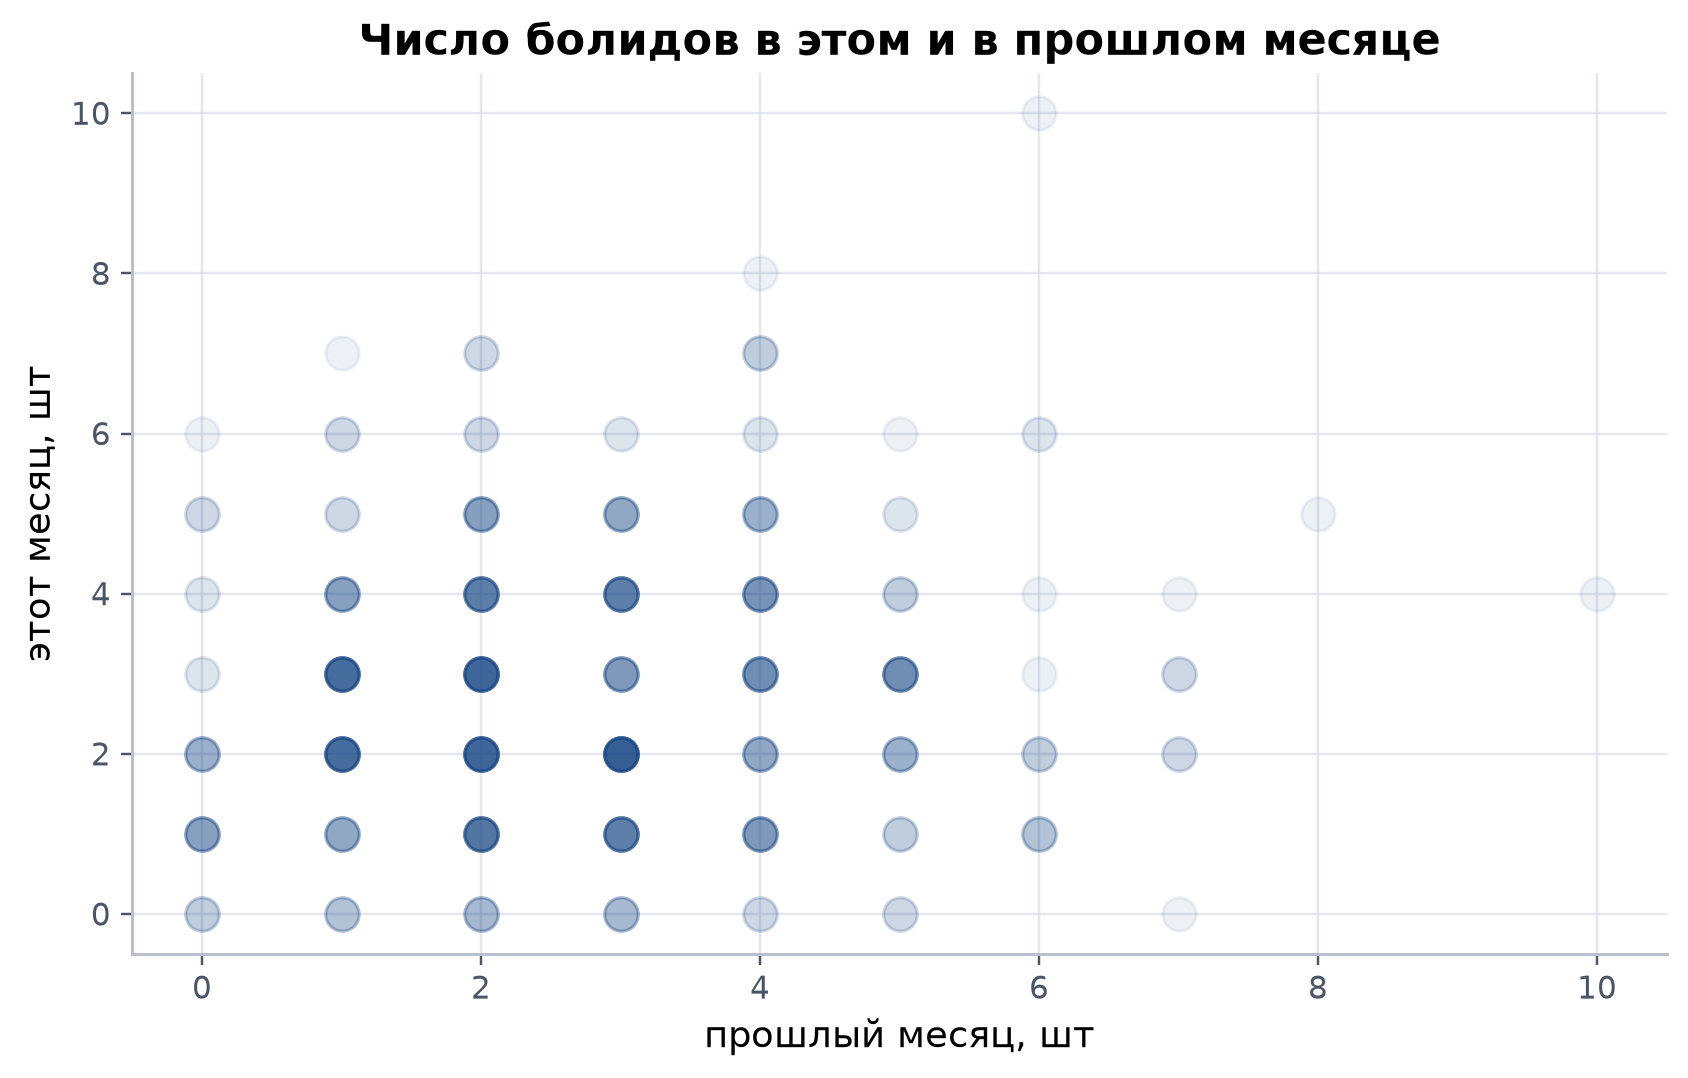

корреляция Спирмена с прошлым месяцем: 0.079  p-value: 0.118


In [30]:
# 2. можно ли угадать число по прошлому месяцу
prev_month = monthly.values[:-1]
next_month = monthly.values[1:]

# значения целые, поэтому одинаковые точки накладываются друг на друга
# чтобы было видно где их много, рисуем полупрозрачные крупные точки
plt.scatter(prev_month, next_month, s=120, color=C_DATA, alpha=0.08)
plt.title("Число болидов в этом и в прошлом месяце")
plt.xlabel("прошлый месяц, шт")
plt.ylabel("этот месяц, шт")
plt.show()

r, p = stats.spearmanr(prev_month, next_month)
print("корреляция Спирмена с прошлым месяцем:", round(r, 3), " p-value:", round(p, 3))

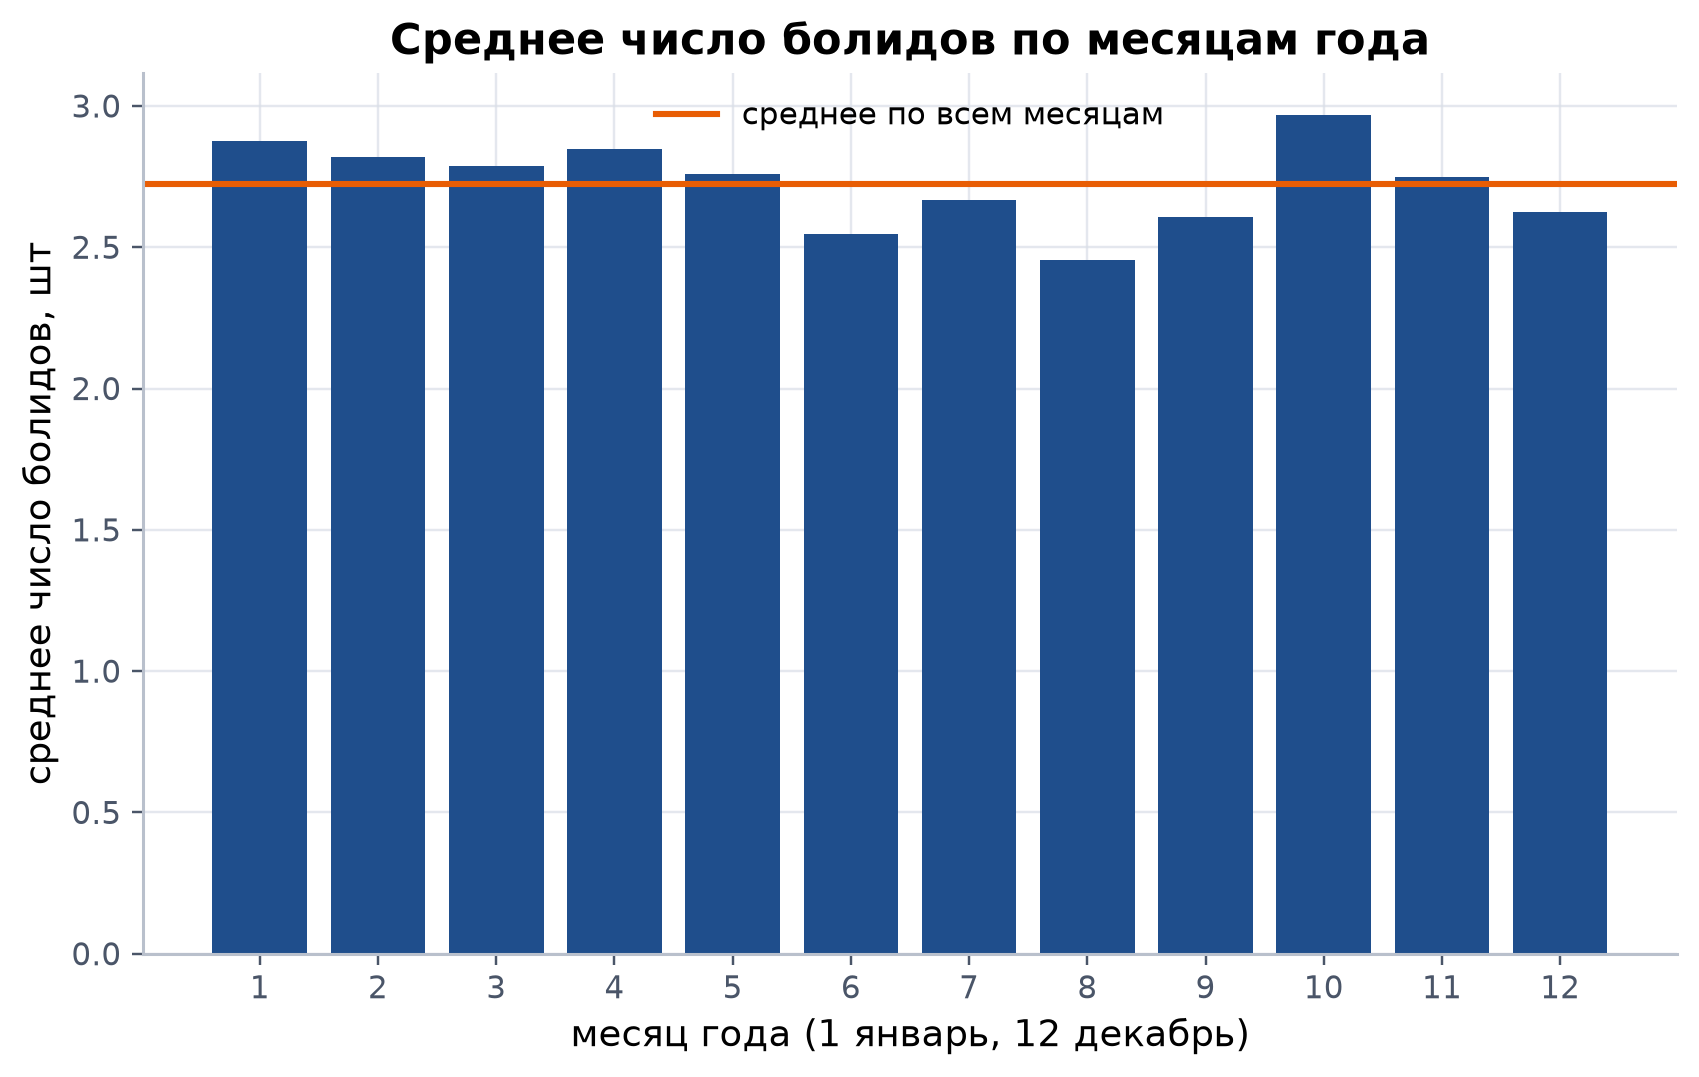

от 2.45 до 2.97 болидов в среднем
критерий Краскела-Уоллиса: статистика 2.66  p-value: 0.995


In [31]:
# 3. зависит ли число от времени года
calendar_month = np.array([m.month for m in monthly.index])
by_month = pd.Series(monthly.values).groupby(calendar_month).mean()

plt.bar(by_month.index, by_month.values, color=C_DATA)
plt.axhline(monthly.mean(), color=C_THEORY, label="среднее по всем месяцам")
plt.title("Среднее число болидов по месяцам года")
plt.xlabel("месяц года (1 январь, 12 декабрь)")
plt.ylabel("среднее число болидов, шт")
plt.xticks(range(1, 13))
plt.legend()
plt.show()

# критерий Краскела-Уоллиса: проверяет отличаются ли между собой 12 групп (январи, феврали и так далее)
groups = [monthly.values[calendar_month == m] for m in range(1, 13)]
H, p = stats.kruskal(*groups)
print("от", round(by_month.min(), 2), "до", round(by_month.max(), 2), "болидов в среднем")
print("критерий Краскела-Уоллиса: статистика", round(H, 2), " p-value:", round(p, 3))

С годами болидов за месяц стало чуть больше: в 1994-1999 в среднем 1.85, а потом 2.92. Наверное раньше их просто хуже записывали. От прошлого месяца число не зависит, корреляция почти ноль (0.079). От времени года тоже не зависит, в любом месяце года в среднем от 2.45 до 2.97 болидов. Получается угадать сколько болидов будет в следующем месяце нельзя, значит величина случайная.

### EDA & Distribution

In [32]:
# описательные статистики
q1m = monthly.quantile(0.25)
q3m = monthly.quantile(0.75)

month_stats = pd.Series({
    "количество месяцев": len(monthly),
    "среднее, шт": monthly.mean(),
    "медиана, шт": monthly.median(),
    "дисперсия, шт^2": monthly.var(),
    "стандартное отклонение, шт": monthly.std(),
    "минимум, шт": monthly.min(),
    "первый квартиль, шт": q1m,
    "третий квартиль, шт": q3m,
    "максимум, шт": monthly.max(),
    "межквартильный размах, шт": q3m - q1m,
    "асимметрия": monthly.skew(),
    "эксцесс": monthly.kurt(),
})
month_stats.round(3)

количество месяцев            392.000
среднее, шт                     2.724
медиана, шт                     3.000
дисперсия, шт^2                 2.850
стандартное отклонение, шт      1.688
минимум, шт                     0.000
первый квартиль, шт             2.000
третий квартиль, шт             4.000
максимум, шт                   10.000
межквартильный размах, шт       2.000
асимметрия                      0.644
эксцесс                         0.521
dtype: float64

{0: 28, 1: 69, 2: 97, 3: 82, 4: 59, 5: 33, 6: 14, 7: 8, 8: 1, 10: 1}


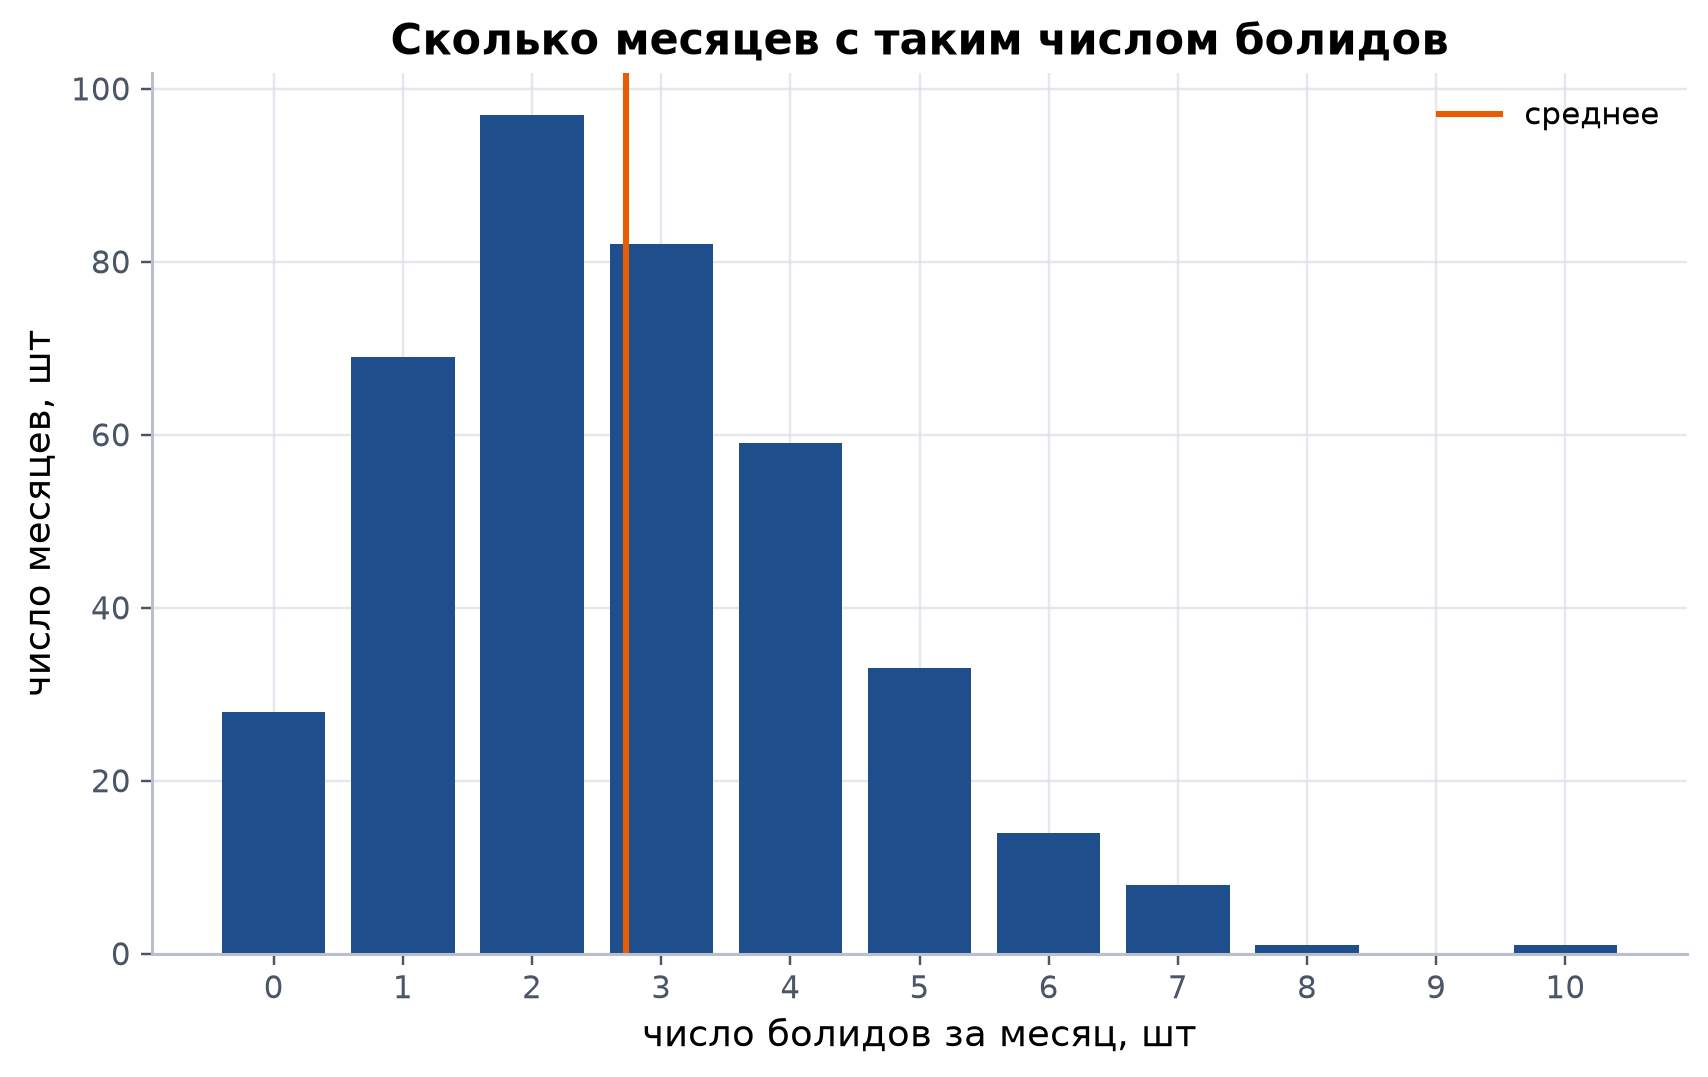

In [33]:
# сколько раз встретилось каждое значение
freq = monthly.value_counts().sort_index()
print(freq.to_dict())

plt.bar(freq.index, freq.values, color=C_DATA)
plt.axvline(monthly.mean(), color=C_THEORY, label="среднее")
plt.title("Сколько месяцев с таким числом болидов")
plt.xlabel("число болидов за месяц, шт")
plt.ylabel("число месяцев, шт")
plt.xticks(range(0, monthly.max() + 1))
plt.legend()
plt.show()

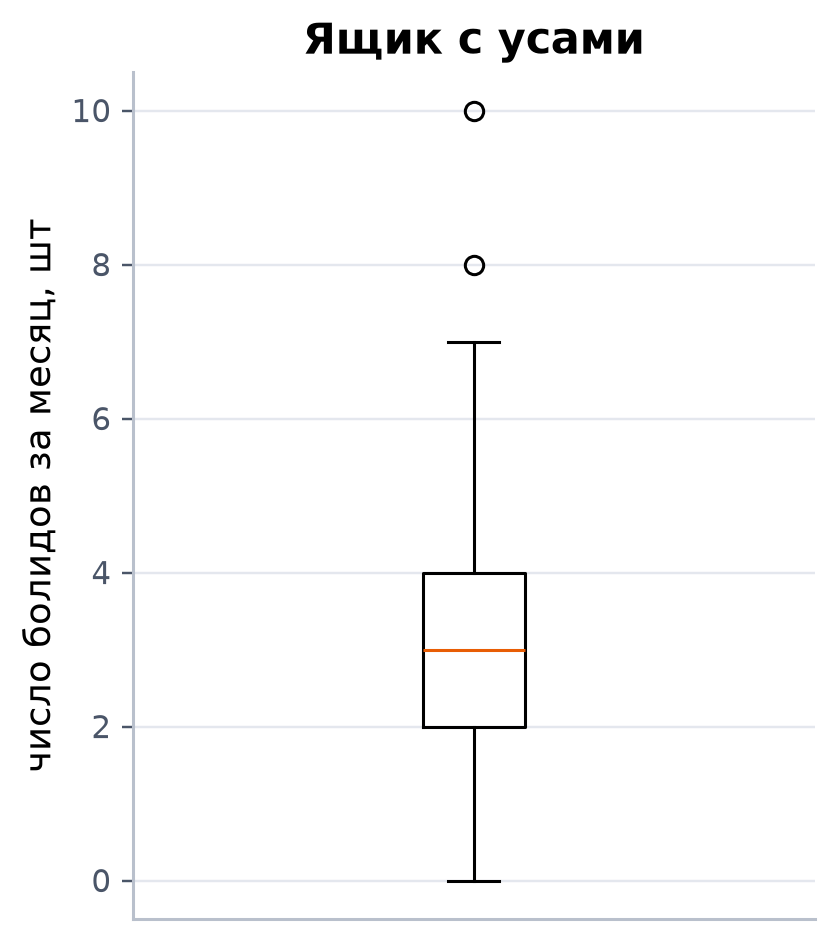

верхняя граница, шт: 7.0
месяцев выше границы: 2 из 392
2000-06     8
2005-04    10
Freq: M, Name: count, dtype: int64


In [34]:
# ящик с усами и выбросы по правилу полутора размахов
plt.figure(figsize=(4, 5))
plt.boxplot(monthly.values)
plt.title("Ящик с усами")
plt.ylabel("число болидов за месяц, шт")
plt.xticks([])
plt.show()

upper_m = q3m + 1.5 * (q3m - q1m)
print("верхняя граница, шт:", upper_m)
print("месяцев выше границы:", (monthly > upper_m).sum(), "из", len(monthly))
print(monthly[monthly > upper_m])

Чаще всего в месяце 2 болида, таких месяцев 97. Потом идут 3 болида и 1 болид. Месяцев вообще без болидов 28. Среднее 2.724 и дисперсия 2.850, они почти одинаковые. Хвост справа есть, но небольшой. Выбросов всего два: июнь 2000 где было 8 болидов и апрель 2005 где было 10. Мы их оставляем, это же настоящие данные.

#### Распределение

Число редких независимых событий за одинаковые промежутки времени описывает распределение Пуассона:

$$P(X = k) = \frac{\lambda^k e^{-\lambda}}{k!}, \quad k = 0, 1, 2, \dots$$

$$E[X] = \lambda, \qquad D[X] = \lambda, \qquad A = \frac{1}{\sqrt{\lambda}}$$

Здесь $P(X = k)$ вероятность что за месяц будет ровно $k$ болидов, $\lambda$ среднее число болидов за месяц, $E[X]$ математическое ожидание, $D[X]$ дисперсия, $A$ асимметрия. Главная особенность: математическое ожидание равно дисперсии.

Связь с первой величиной: если интервалы между событиями распределены экспоненциально, то число событий за промежуток времени распределено по Пуассону.

лямбда, болидов за месяц: 2.724


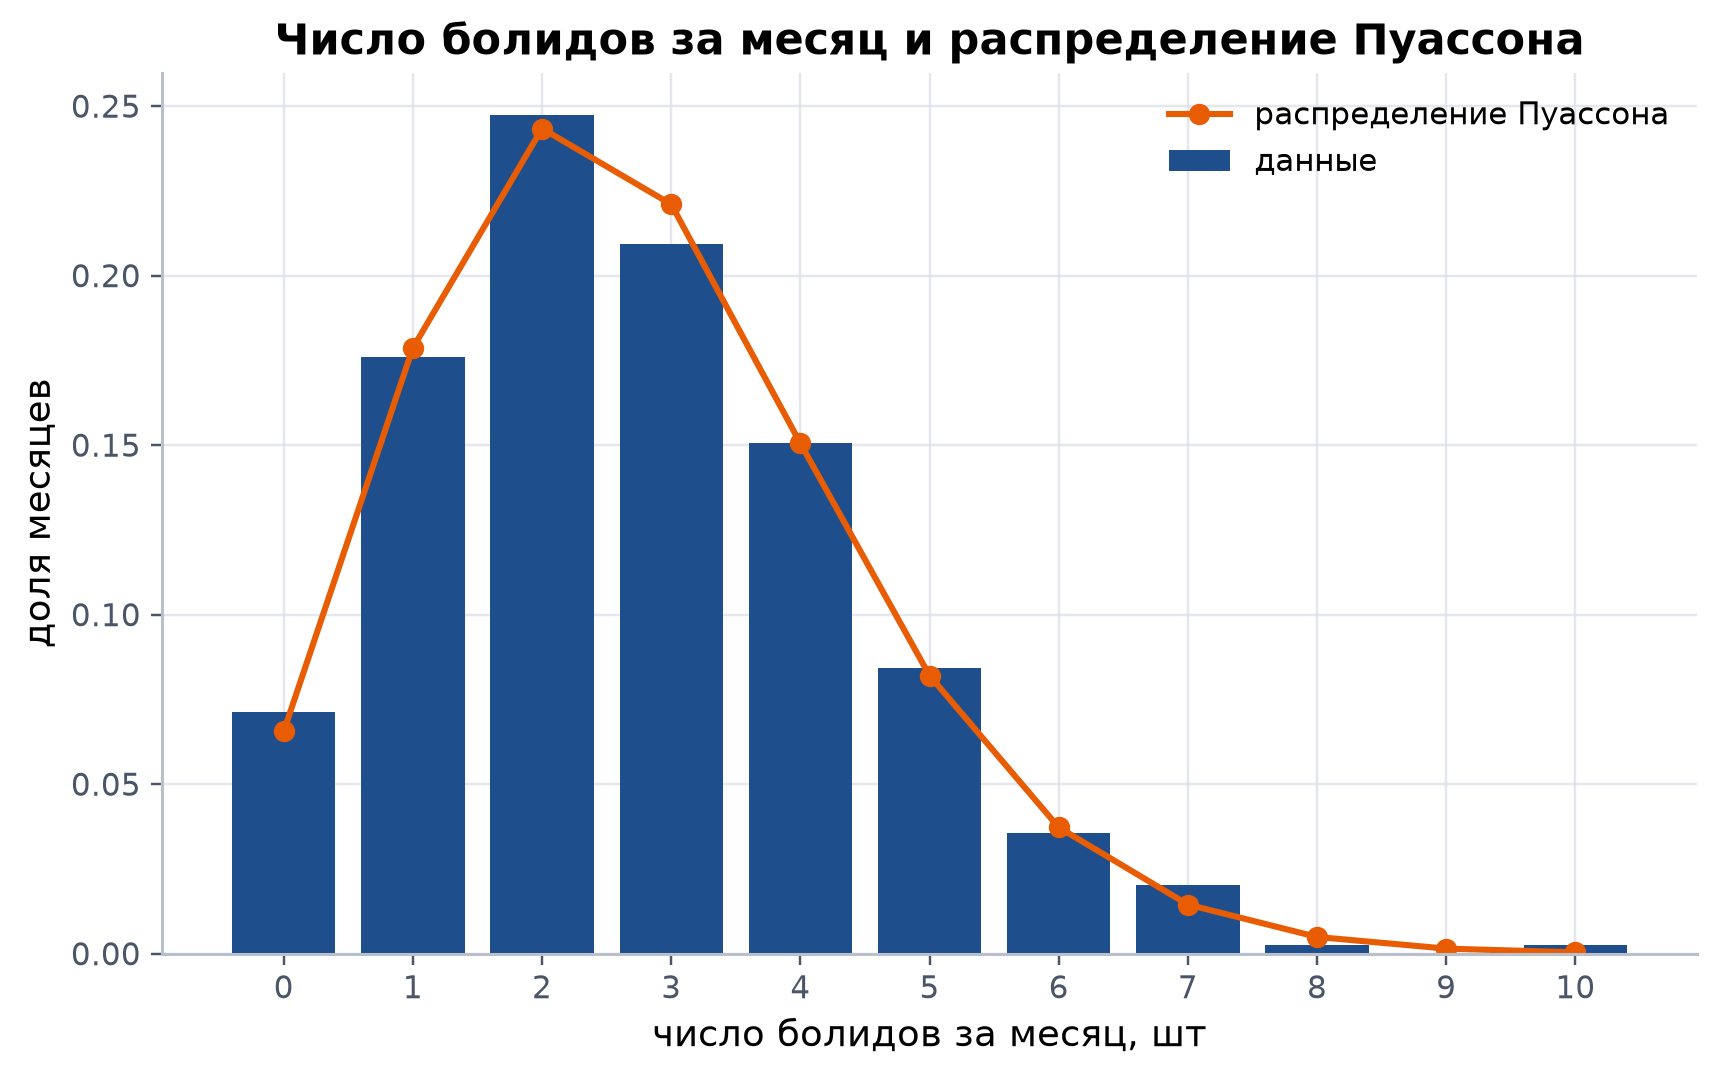

In [35]:
# параметр лямбда это среднее число болидов за месяц
lam_m = monthly.mean()
print("лямбда, болидов за месяц:", round(lam_m, 3))

# доля месяцев с каждым значением и вероятности по формуле Пуассона
k = np.arange(0, monthly.max() + 1)
share = monthly.value_counts(normalize=True).reindex(k, fill_value=0)

plt.bar(k, share.values, color=C_DATA, label="данные")
plt.plot(k, stats.poisson.pmf(k, lam_m), "o-", color=C_THEORY, label="распределение Пуассона")
plt.title("Число болидов за месяц и распределение Пуассона")
plt.xlabel("число болидов за месяц, шт")
plt.ylabel("доля месяцев")
plt.xticks(k)
plt.legend()
plt.show()

In [36]:
# сравниваем числа из данных с формулами
compare_m = pd.DataFrame({
    "по данным": [monthly.mean(), monthly.var(), monthly.skew()],
    "по формулам": [lam_m, lam_m, 1 / np.sqrt(lam_m)],
}, index=["среднее, шт", "дисперсия, шт^2", "асимметрия"])
print(compare_m.round(3))

# проверка связи с интервалами: в месяце в среднем 30.44 дня
print()
print("средний интервал, дни:", round(gaps.mean(), 2))
print("тогда болидов за месяц должно быть 30.44 / средний интервал =", round(30.44 / gaps.mean(), 3))
print("по данным среднее за месяц:", round(monthly.mean(), 3))

                 по данным  по формулам
среднее, шт          2.724        2.724
дисперсия, шт^2      2.850        2.724
асимметрия           0.644        0.606

средний интервал, дни: 11.17
тогда болидов за месяц должно быть 30.44 / средний интервал = 2.725
по данным среднее за месяц: 2.724


Распределение Пуассона подходит когда события редкие и не зависят друг от друга, у болидов так и есть. Оранжевые точки почти везде попали на столбики. У Пуассона среднее должно быть равно дисперсии, у нас 2.724 и 2.850, это очень близко. Еще это сходится с первой величиной: между болидами в среднем 11.17 дня, значит за месяц их должно быть 30.44 / 11.17 = 2.725, а у нас по данным 2.724.

#### Проверка гипотезы

$H_0$: число болидов за месяц распределено по Пуассону с параметром $\lambda$.

$H_1$: распределение другое.

Уровень значимости $\alpha = 0.05$. Величина дискретная, поэтому проверяем критерием хи-квадрат: сравниваем сколько месяцев с каждым значением получилось и сколько должно быть по формуле.

$$\chi^2 = \sum \frac{(O_i - E_i)^2}{E_i}$$

где $O_i$ сколько месяцев наблюдали, $E_i$ сколько ожидали по Пуассону. Значения 7 и больше объединяем в одну группу, потому что таких месяцев мало.

In [37]:
# наблюдаемые и ожидаемые числа месяцев для значений 0, 1, ..., 6 и "7 и больше"
observed = [(monthly == j).sum() for j in range(7)] + [(monthly >= 7).sum()]
expected = [stats.poisson.pmf(j, lam_m) * len(monthly) for j in range(7)] + [stats.poisson.sf(6, lam_m) * len(monthly)]

chi_table = pd.DataFrame({"наблюдали": observed, "ожидали": np.round(expected, 1)},
                         index=["0", "1", "2", "3", "4", "5", "6", "7 и больше"])
print(chi_table)

chi2 = sum((o - e) ** 2 / e for o, e in zip(observed, expected))
# степеней свободы: 8 групп минус 1 и минус 1 за параметр лямбда который оценили по данным
dof = len(observed) - 1 - 1
p_value_m = stats.chi2.sf(chi2, dof)

print()
print("статистика хи-квадрат:", round(chi2, 3))
print("степеней свободы:", dof)
print("p-value:", round(p_value_m, 3))

            наблюдали  ожидали
0                  28     25.7
1                  69     70.0
2                  97     95.4
3                  82     86.6
4                  59     59.0
5                  33     32.2
6                  14     14.6
7 и больше         10      8.4

статистика хи-квадрат: 0.841
степеней свободы: 6
p-value: 0.991


Проверяли что число болидов за месяц распределено по Пуассону. Взяли критерий хи-квадрат, потому что числа тут целые. В таблице видно что наблюдали и ожидали почти одно и то же, например месяцев с 4 болидами 59 и ожидали тоже 59. P-value получилось 0.991, это намного больше 0.05. Значит гипотезу не отвергаем, Пуассон подходит.

### Independence & Estimations

#### Зависимость от первой величины

Интервалы между болидами и число болидов за месяц это величины одной природы, обе посчитаны из дат. Проверяем связаны ли они: для каждого месяца берем средний интервал перед болидами этого месяца и число болидов в нем.

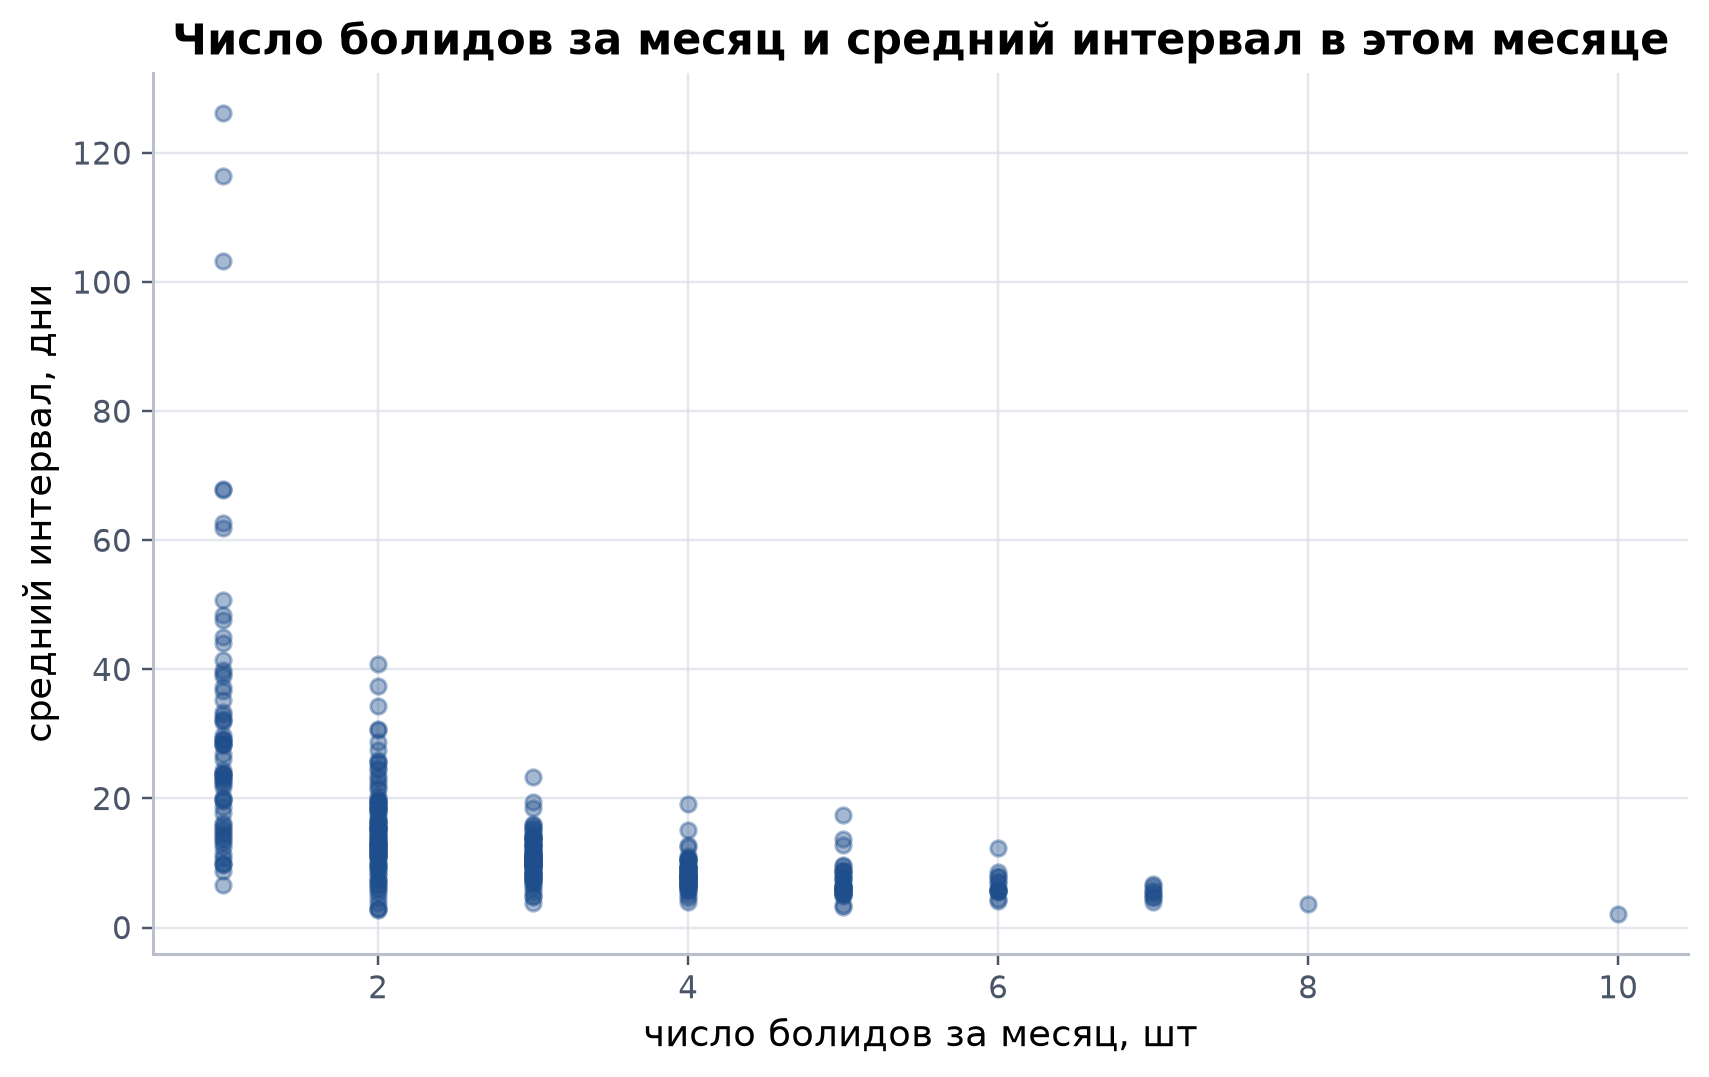

месяцев в сравнении: 363
корреляция Спирмена: -0.739  p-value: 8.062852024695233e-64


In [38]:
# средний интервал перед болидами каждого месяца
gap_by_month = df.dropna(subset=["gap_days"]).groupby(df["date"].dt.to_period("M"))["gap_days"].mean()

# в месяцах без болидов среднего интервала нет, они отбрасываются
both = pd.DataFrame({"count": monthly, "mean_gap": gap_by_month}).dropna()

plt.scatter(both["count"], both["mean_gap"], s=25, color=C_DATA, alpha=0.4)
plt.title("Число болидов за месяц и средний интервал в этом месяце")
plt.xlabel("число болидов за месяц, шт")
plt.ylabel("средний интервал, дни")
plt.show()

r, p = stats.spearmanr(both["count"], both["mean_gap"])
print("месяцев в сравнении:", len(both))
print("корреляция Спирмена:", round(r, 3), " p-value:", p)

Эти две величины зависят друг от друга. Корреляция -0.739, это сильная связь. Минус значит что когда в месяце много болидов, интервалы между ними короче. Так и должно быть, ведь обе величины посчитаны из одних и тех же дат. Месяцы без болидов сюда не вошли, для них интервал не посчитать.

#### Выборка и генеральная совокупность

Генеральная совокупность это все 392 месяца. Берем выборку из 100 месяцев без возвращения и с возвращением.

                 все 392 месяца  выборка без возвращения  \
среднее, шт               2.724                    2.630   
медиана, шт               3.000                    3.000   
дисперсия, шт^2           2.850                    2.134   

                 выборка с возвращением  
среднее, шт                       2.840  
медиана, шт                       3.000  
дисперсия, шт^2                   3.025  


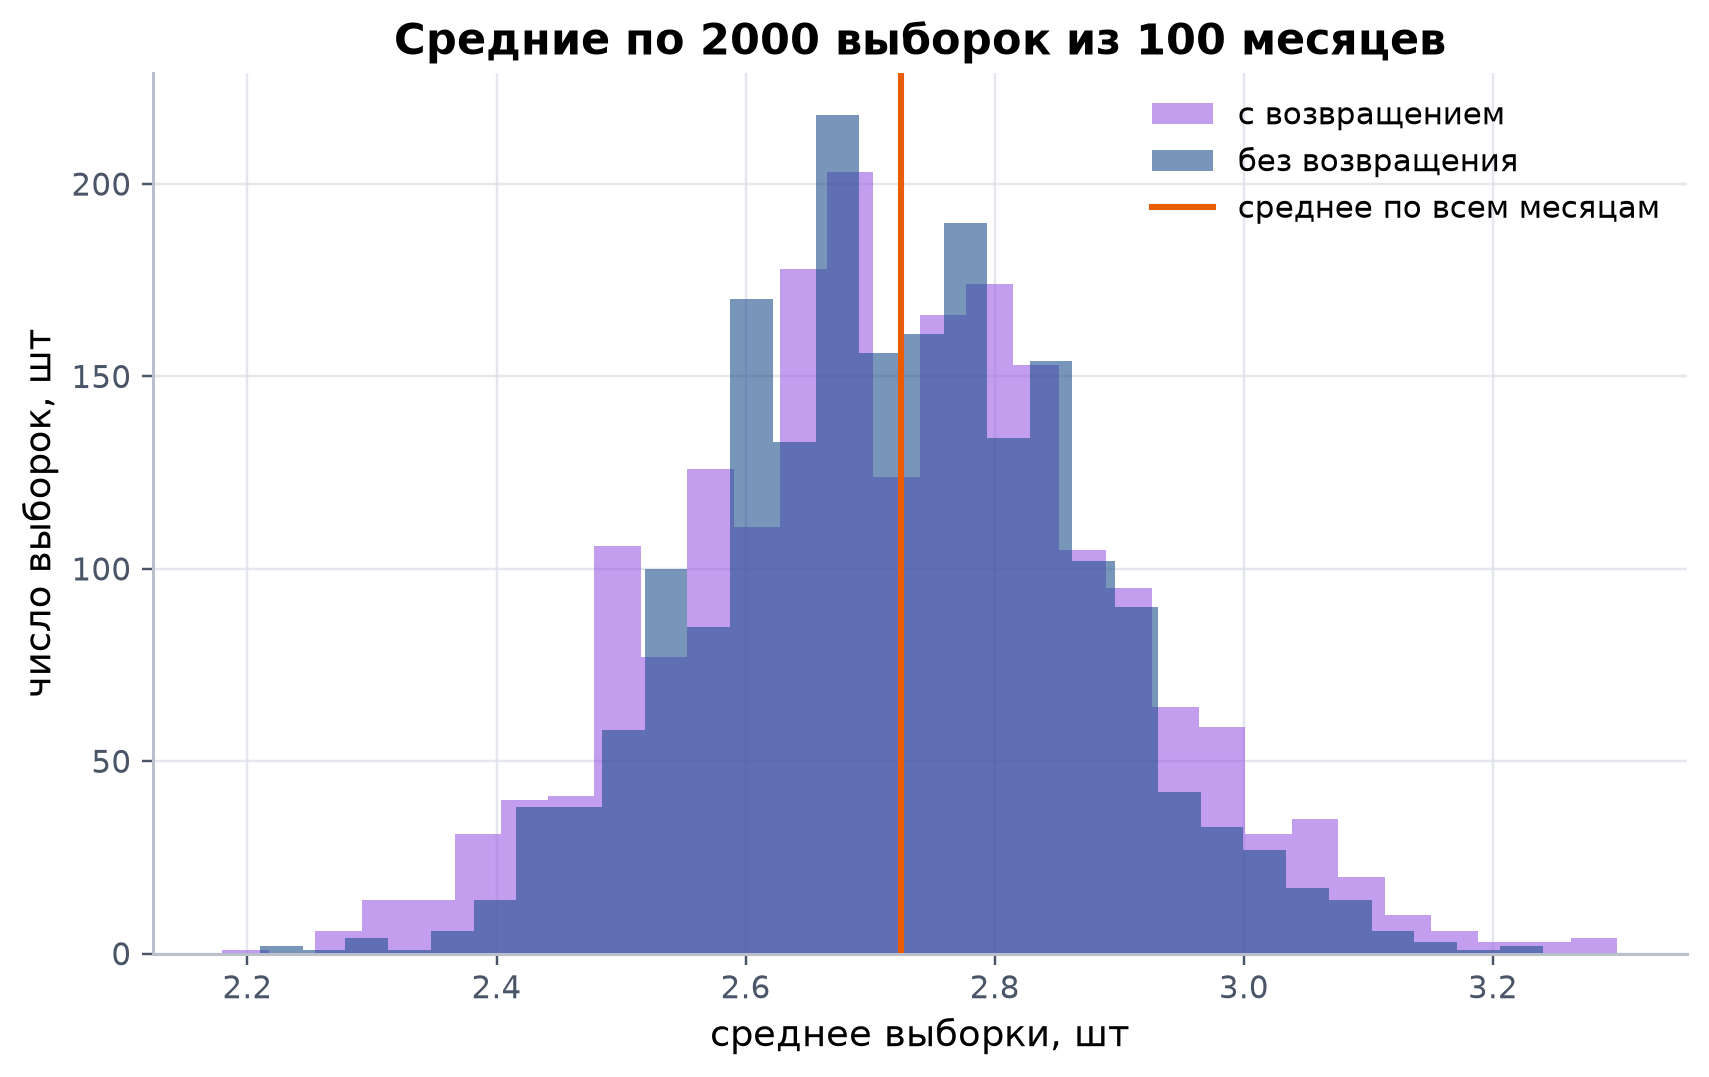

среднее по всем месяцам: 2.724
без возвращения: среднее средних 2.722  разброс (ст. отклонение) 0.148
с возвращением:  среднее средних 2.722  разброс (ст. отклонение) 0.173


In [39]:
n_m = 100

sample_without_m = monthly.sample(n_m, replace=False, random_state=1)
sample_with_m = monthly.sample(n_m, replace=True, random_state=1)

sample_table_m = pd.DataFrame({
    "все 392 месяца": [monthly.mean(), monthly.median(), monthly.var()],
    "выборка без возвращения": [sample_without_m.mean(), sample_without_m.median(), sample_without_m.var()],
    "выборка с возвращением": [sample_with_m.mean(), sample_with_m.median(), sample_with_m.var()],
}, index=["среднее, шт", "медиана, шт", "дисперсия, шт^2"])
print(sample_table_m.round(3))

# по 2000 выборок каждым способом
means_without_m = [monthly.sample(n_m, replace=False, random_state=i).mean() for i in range(2000)]
means_with_m = [monthly.sample(n_m, replace=True, random_state=i).mean() for i in range(2000)]

plt.hist(means_with_m, bins=30, alpha=0.6, color=C_ACCENT, label="с возвращением")
plt.hist(means_without_m, bins=30, alpha=0.6, color=C_DATA, label="без возвращения")
plt.axvline(monthly.mean(), color=C_THEORY, label="среднее по всем месяцам")
plt.title("Средние по 2000 выборок из 100 месяцев")
plt.xlabel("среднее выборки, шт")
plt.ylabel("число выборок, шт")
plt.legend()
plt.show()

print("среднее по всем месяцам:", round(monthly.mean(), 3))
print("без возвращения: среднее средних", round(np.mean(means_without_m), 3), " разброс (ст. отклонение)", round(np.std(means_without_m), 3))
print("с возвращением:  среднее средних", round(np.mean(means_with_m), 3), " разброс (ст. отклонение)", round(np.std(means_with_m), 3))

Выборка из 100 месяцев получилась похожа на все данные: среднее 2.630 и 2.840, а по всем месяцам 2.724. Дисперсия отличается сильнее. Когда взяли по 2000 выборок, их средние оказались вокруг 2.722, то есть почти ровно где надо. У выборок без возвращения разброс опять меньше (0.148 против 0.173). Значит по 100 месяцам можно судить о всех.

#### Состоятельность оценок

Смотрим на среднее и на дисперсию: у распределения Пуассона они должны сходиться к одному и тому же числу.

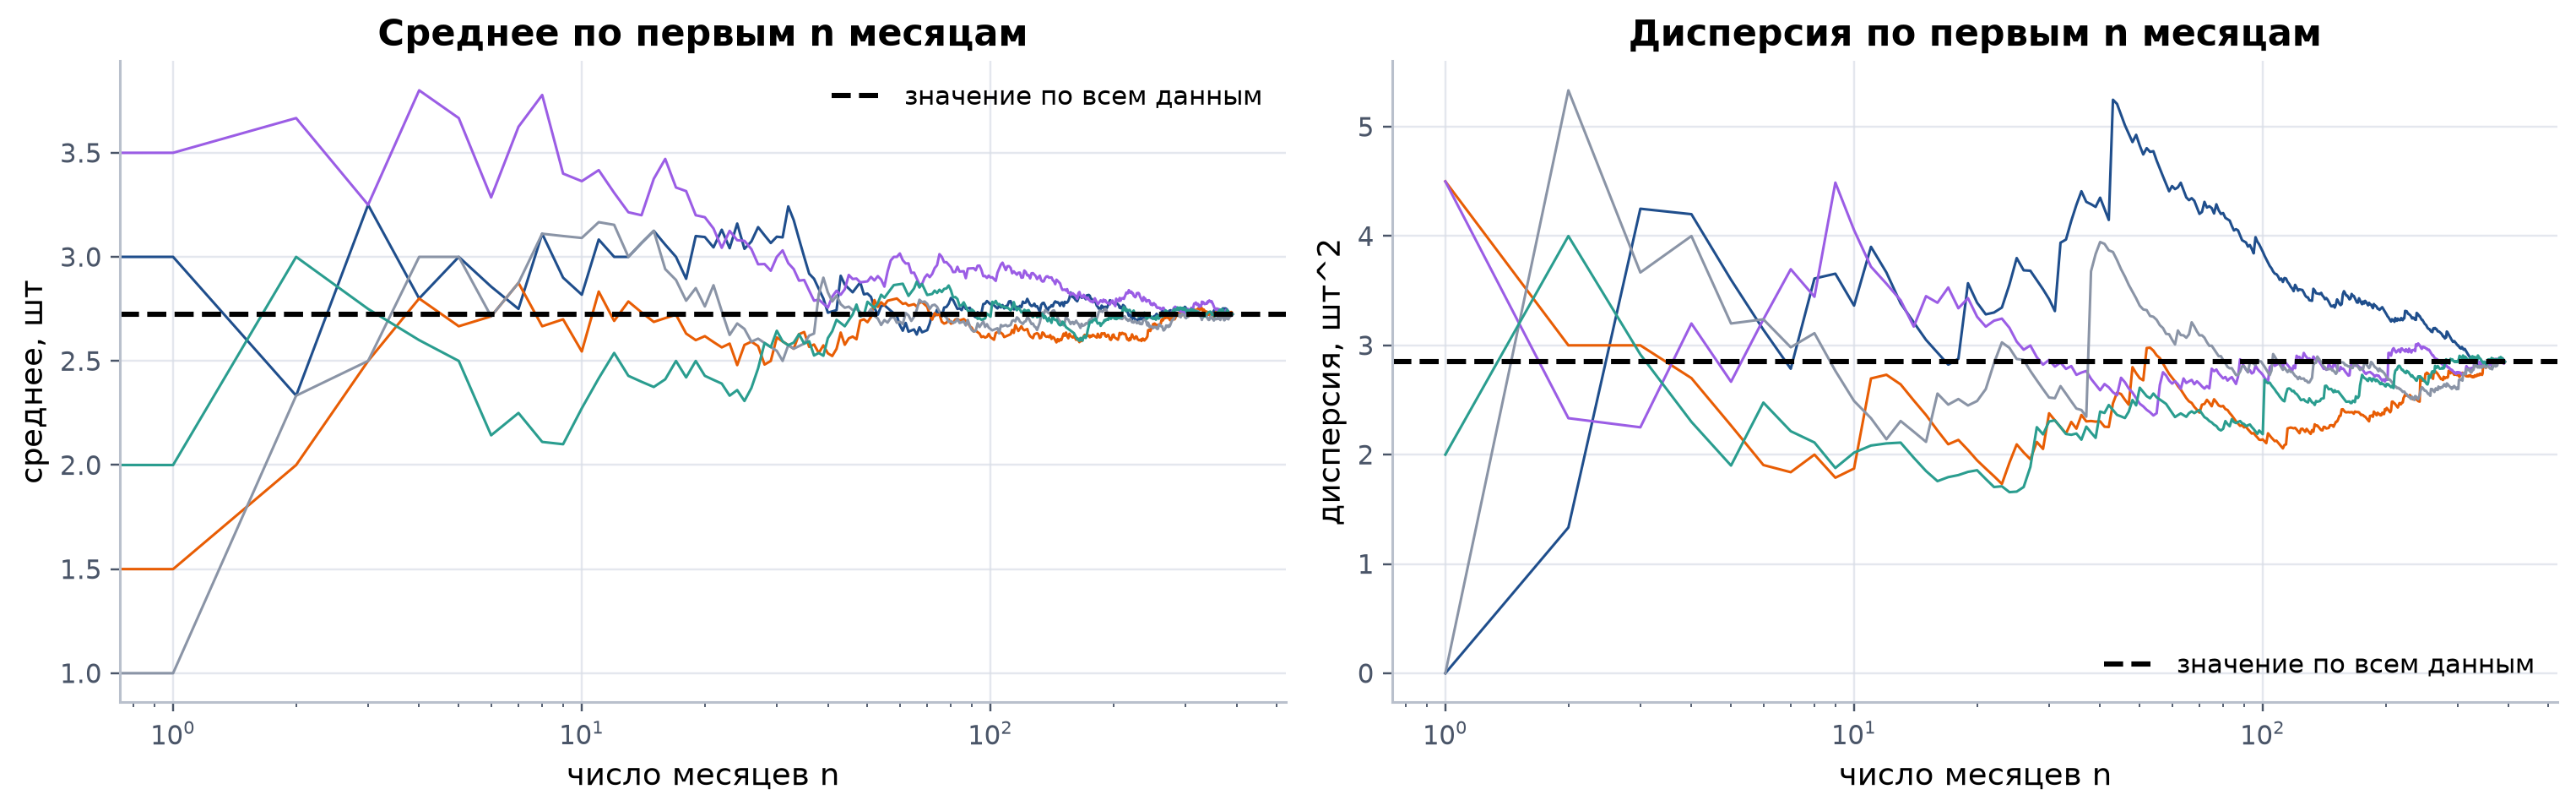

n = 10  среднее: 2.9  дисперсия: 3.66
n = 50  среднее: 2.82  дисперсия: 4.93
n = 100  среднее: 2.78  дисперсия: 3.89
n = 200  среднее: 2.78  дисперсия: 3.31
n = 392  среднее: 2.72  дисперсия: 2.85


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for seed in range(5):
    shuffled_m = monthly.sample(frac=1, random_state=seed).reset_index(drop=True)
    axes[0].plot(shuffled_m.expanding().mean(), linewidth=1)
    axes[1].plot(shuffled_m.expanding().var(), linewidth=1)

axes[0].axhline(monthly.mean(), color="black", linestyle="--", label="значение по всем данным")
axes[0].set_title("Среднее по первым n месяцам")
axes[0].set_ylabel("среднее, шт")
axes[1].axhline(monthly.var(), color="black", linestyle="--", label="значение по всем данным")
axes[1].set_title("Дисперсия по первым n месяцам")
axes[1].set_ylabel("дисперсия, шт^2")
for ax in axes:
    ax.set_xlabel("число месяцев n")
    ax.set_xscale("log")
    ax.legend()
plt.tight_layout()
plt.show()

shuffled_m = monthly.sample(frac=1, random_state=0).reset_index(drop=True)
for j in [10, 50, 100, 200, 392]:
    print("n =", j, " среднее:", round(shuffled_m[:j].mean(), 2), " дисперсия:", round(shuffled_m[:j].var(), 2))

Когда месяцев мало, линии сильно скачут, особенно у дисперсии. Чем больше месяцев, тем ближе они к пунктиру. Среднее приходит к 2.72, дисперсия к 2.85, но дисперсия дольше не может успокоиться. Получается обе оценки состоятельные. И приходят они почти к одному числу, как и должно быть у Пуассона.

## Random Variable 03 (широта точки падения)

### Description

In [41]:
# широта известна не у всех болидов, берем только те где она есть
lat = df["lat"].dropna().reset_index(drop=True)

print("болидов с известной широтой:", len(lat), "из", len(df))
print("самая южная точка, градусы:", lat.min())
print("самая северная точка, градусы:", lat.max())
print("в северном полушарии:", (lat > 0).sum(), " в южном:", (lat < 0).sum())

болидов с известной широтой: 883 из 1069
самая южная точка, градусы: -85.0
самая северная точка, градусы: 88.5
в северном полушарии: 434  в южном: 448


Широта меняется от $-90°$ (южный полюс) до $90°$ (северный полюс). Если болиды падают на Землю куда попало, то в каждую полоску между двумя широтами должно попадать столько болидов, какая у этой полоски площадь. Площадь полоски на шаре от широты $\varphi_1$ до $\varphi_2$ равна

$$S = 2\pi R^2 (\sin\varphi_2 - \sin\varphi_1)$$

где $R$ радиус Земли. То есть площадь зависит от разности синусов. Поэтому дальше смотрим не только на саму широту $\varphi$, но и на ее синус $\sin\varphi$: если болиды падают равномерно по поверхности, то синус широты должен быть распределен равномерно от $-1$ до $1$.

In [42]:
# синус широты (np.sin считает в радианах, поэтому переводим градусы в радианы)
sin_lat = np.sin(np.radians(lat))
pd.DataFrame({"широта, градусы": lat, "синус широты": sin_lat}).head()

,"широта, градусы",синус широты
0,2.7,0.047106
1,52.8,0.796530
2,45.5,0.713250
3,-45.2,-0.709571
4,-1.5,-0.026177


Третья величина это широта места где вспыхнул болид, в градусах. Она известна не у всех, у нас таких 883 болида из 1069. Значения от -85 до 88.5, то есть болиды есть почти от полюса до полюса. В северном полушарии 434 болида, в южном 448, почти поровну. Кроме самой широты мы считаем ее синус, потому что по формуле выше площадь полоски на шаре зависит от синуса. Если болиды падают куда попало, то синус должен быть распределен равномерно.

#### Случайная ли это величина

Проверяем меняется ли широта с годами, зависит ли от широты предыдущего болида и от других столбцов.

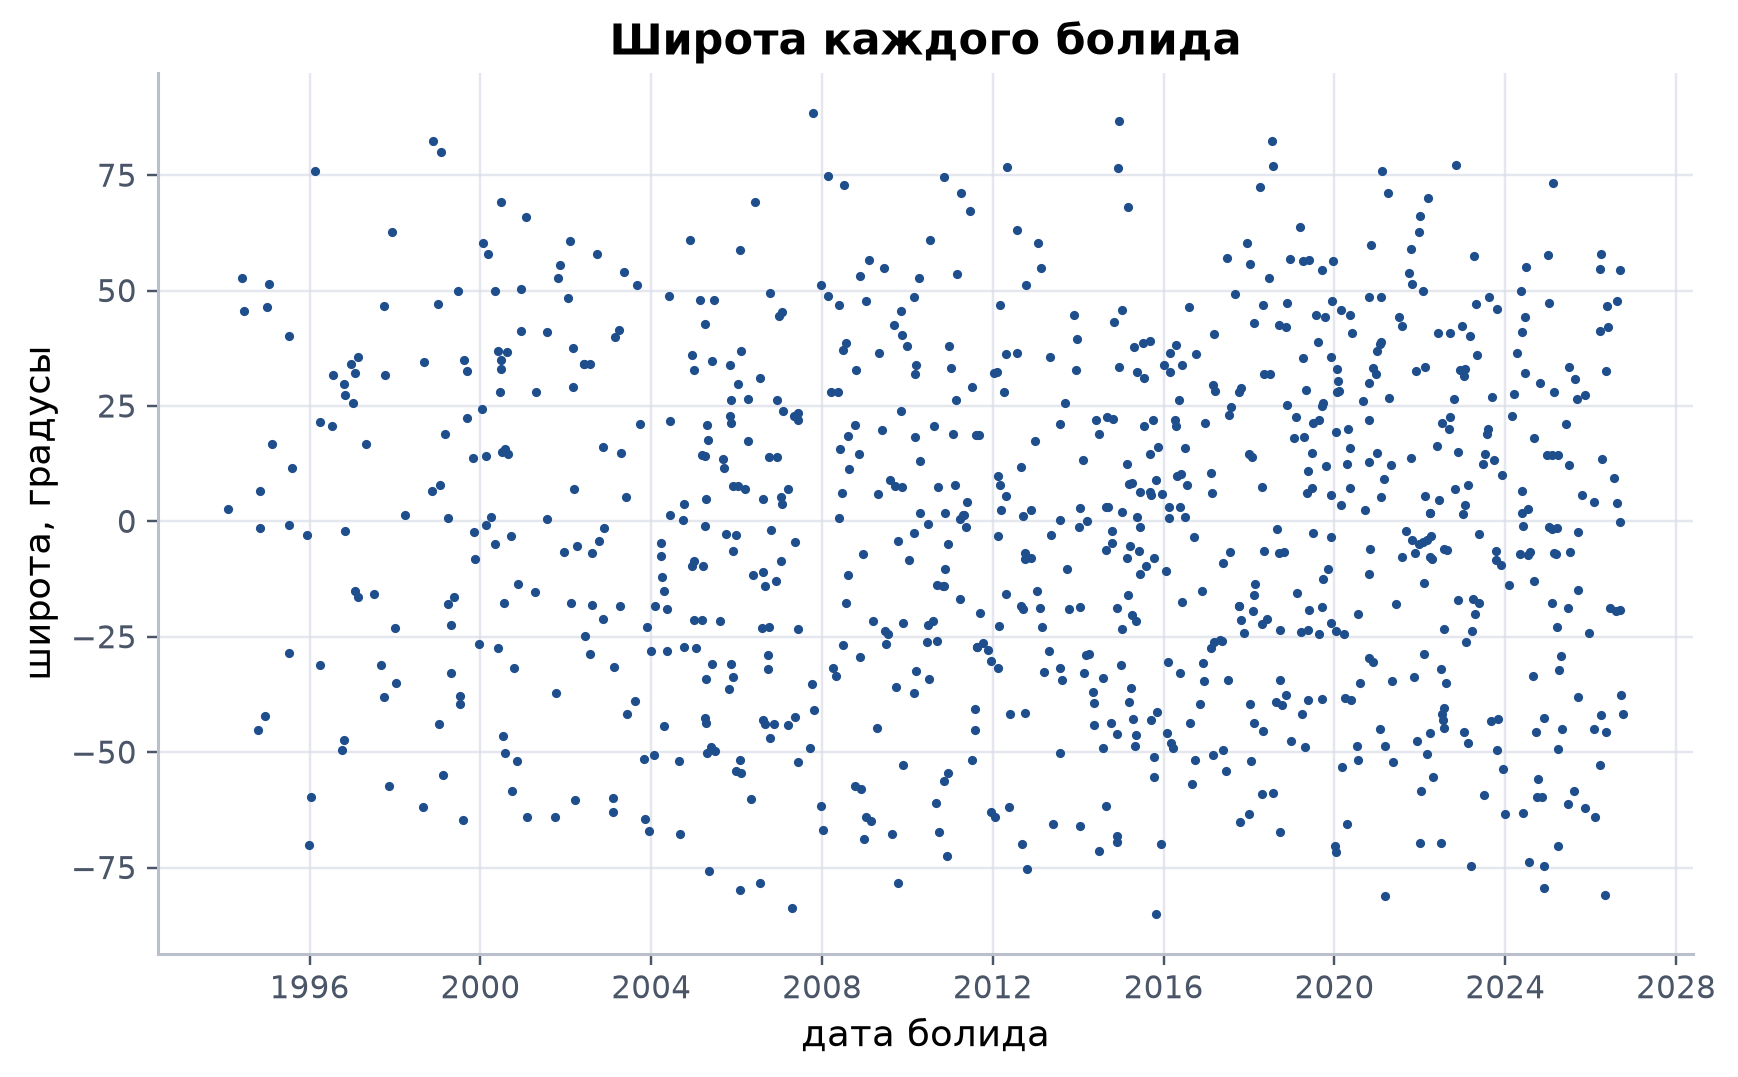

корреляция Спирмена с номером по порядку: -0.011  p-value: 0.751


In [43]:
lat_rows = df.dropna(subset=["lat"]).reset_index(drop=True)

# 1. широта болидов во времени
plt.plot(lat_rows["date"], lat_rows["lat"], ".", color=C_DATA, markersize=4)
plt.title("Широта каждого болида")
plt.xlabel("дата болида")
plt.ylabel("широта, градусы")
plt.show()

r, p = stats.spearmanr(np.arange(len(lat)), lat)
print("корреляция Спирмена с номером по порядку:", round(r, 3), " p-value:", round(p, 3))

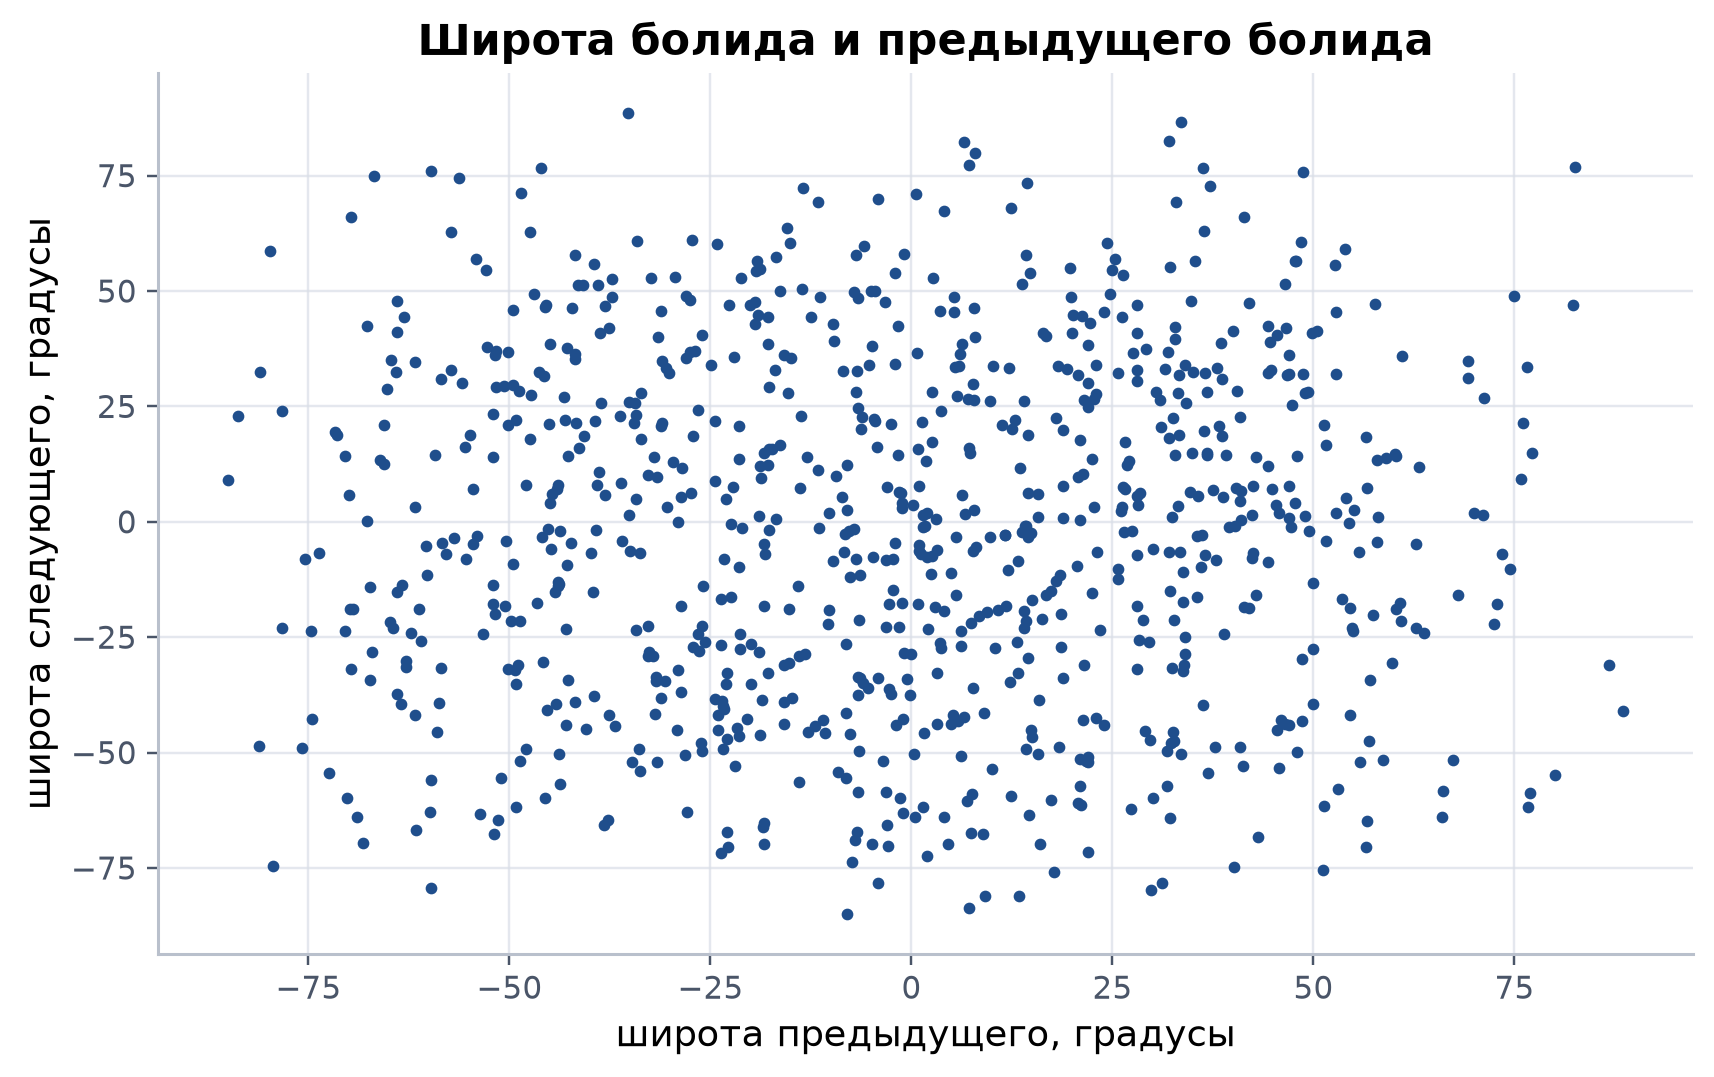

корреляция Спирмена с предыдущим болидом: 0.016  p-value: 0.641
energy_kt  корреляция: -0.011  p-value: 0.752  пар значений: 883
alt_km  корреляция: -0.007  p-value: 0.868  пар значений: 602
vel_kms  корреляция: 0.049  p-value: 0.357  пар значений: 363
gap_days  корреляция: 0.026  p-value: 0.432  пар значений: 882


In [44]:
# 2. широта и широта предыдущего болида
plt.scatter(lat[:-1], lat[1:], s=8, color=C_DATA)
plt.title("Широта болида и предыдущего болида")
plt.xlabel("широта предыдущего, градусы")
plt.ylabel("широта следующего, градусы")
plt.show()

r, p = stats.spearmanr(lat[:-1], lat[1:])
print("корреляция Спирмена с предыдущим болидом:", round(r, 3), " p-value:", round(p, 3))

# 3. широта и другие столбцы
for col in ["energy_kt", "alt_km", "vel_kms", "gap_days"]:
    pair = df[["lat", col]].dropna()
    r, p = stats.spearmanr(pair["lat"], pair[col])
    print(col, " корреляция:", round(r, 3), " p-value:", round(p, 3), " пар значений:", len(pair))

По графику широты во времени ничего не видно, точки разбросаны по всей высоте в любом году. Корреляция с номером по порядку почти ноль (-0.011). От широты предыдущего болида тоже ничего не зависит, корреляция 0.016, на графике просто облако. С энергией, высотой, скоростью и интервалом связи тоже нет, везде корреляция около нуля и p-value больше 0.3. Получается по другим данным широту не посчитать, это случайная величина.

### EDA & Distribution

In [45]:
# описательные статистики для широты и для синуса широты
def describe(x):
    return pd.Series({
        "количество": len(x),
        "среднее": x.mean(),
        "медиана": x.median(),
        "дисперсия": x.var(),
        "стандартное отклонение": x.std(),
        "минимум": x.min(),
        "первый квартиль": x.quantile(0.25),
        "третий квартиль": x.quantile(0.75),
        "максимум": x.max(),
        "асимметрия": x.skew(),
        "эксцесс": x.kurt(),
    })

lat_stats = pd.DataFrame({"широта, градусы": describe(lat), "синус широты": describe(sin_lat)})
lat_stats.round(3)

,"широта, градусы",синус широты
количество,883.000,883.000
среднее,-1.710,-0.023
медиана,-1.200,-0.021
дисперсия,1411.826,0.316
стандартное отклонение,37.574,0.562
минимум,-85.000,-0.996
первый квартиль,-31.100,-0.517
третий квартиль,28.100,0.471
максимум,88.500,1.000
асимметрия,-0.017,-0.003


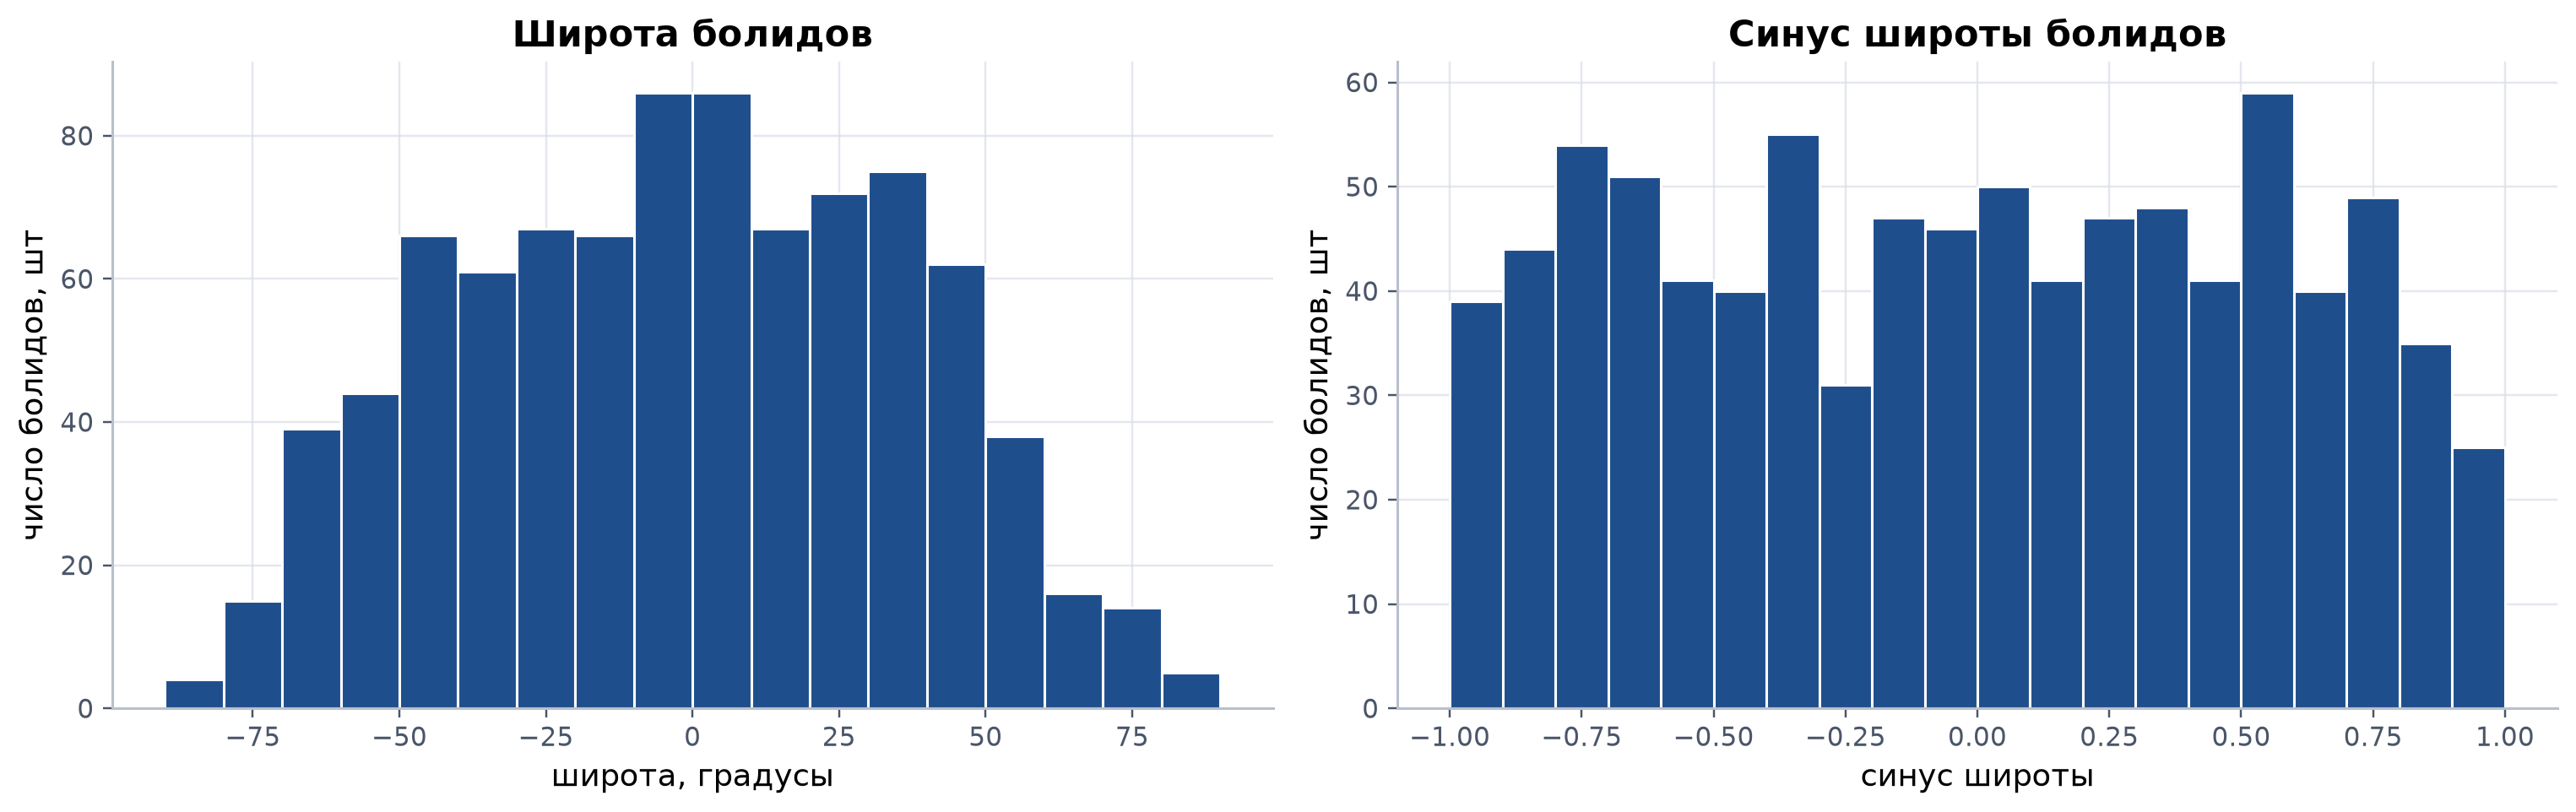

болидов ближе 30 градусов к экватору: 444 из 883
болидов дальше 60 градусов от экватора: 93 из 883


In [46]:
# две гистограммы рядом: сама широта и ее синус
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(lat, bins=18, range=(-90, 90), color=C_DATA, edgecolor="white")
axes[0].set_title("Широта болидов")
axes[0].set_xlabel("широта, градусы")
axes[0].set_ylabel("число болидов, шт")

axes[1].hist(sin_lat, bins=20, range=(-1, 1), color=C_DATA, edgecolor="white")
axes[1].set_title("Синус широты болидов")
axes[1].set_xlabel("синус широты")
axes[1].set_ylabel("число болидов, шт")

plt.tight_layout()
plt.show()

print("болидов ближе 30 градусов к экватору:", (lat.abs() < 30).sum(), "из", len(lat))
print("болидов дальше 60 градусов от экватора:", (lat.abs() > 60).sum(), "из", len(lat))

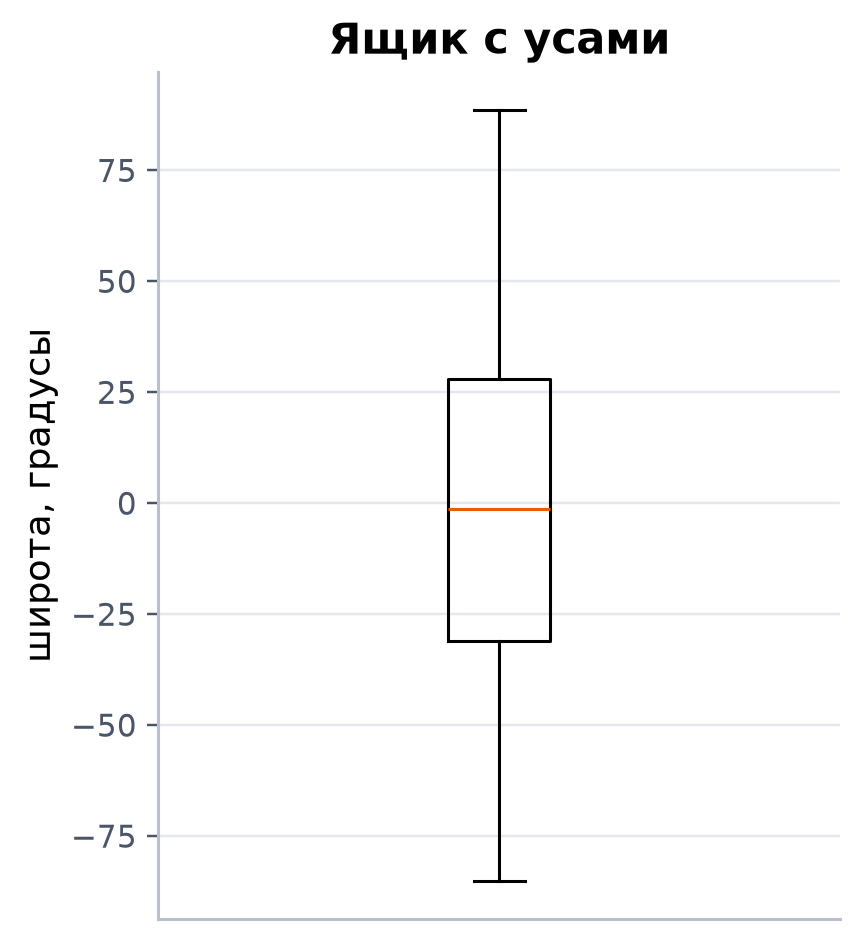

границы выбросов, градусы: -119.9 и 116.9
выбросов: 0


In [47]:
# ящик с усами и выбросы
plt.figure(figsize=(4, 5))
plt.boxplot(lat)
plt.title("Ящик с усами")
plt.ylabel("широта, градусы")
plt.xticks([])
plt.show()

q1l = lat.quantile(0.25)
q3l = lat.quantile(0.75)
low_l = q1l - 1.5 * (q3l - q1l)
high_l = q3l + 1.5 * (q3l - q1l)
print("границы выбросов, градусы:", round(low_l, 1), "и", round(high_l, 1))
print("выбросов:", ((lat < low_l) | (lat > high_l)).sum())

На левой гистограмме видно что больше всего болидов около экватора, а к полюсам их все меньше. Но это не потому что камни целятся в экватор, просто у экватора больше площадь. Ближе 30 градусов к экватору попала половина болидов (444 из 883), а дальше 60 градусов всего 93. На правой гистограмме с синусом столбики уже примерно одной высоты. Среднее широты -1.7 градуса, медиана -1.2, то есть распределение симметричное, асимметрия почти ноль. Выбросов нет вообще, границы получились шире чем сама шкала широты.

#### Распределение

Равномерное распределение на отрезке от $a$ до $b$:

$$f(x) = \frac{1}{b - a}, \quad a \le x \le b \qquad\qquad F(x) = \frac{x - a}{b - a}$$

$$E[X] = \frac{a + b}{2}, \qquad D[X] = \frac{(b - a)^2}{12}, \qquad A = 0$$

Здесь $f(x)$ плотность, $F(x)$ функция распределения, $E[X]$ математическое ожидание, $D[X]$ дисперсия, $A$ асимметрия. Для синуса широты $a = -1$, $b = 1$, поэтому должно быть $f(x) = 0.5$, $E[X] = 0$, $D[X] = 1/3$.

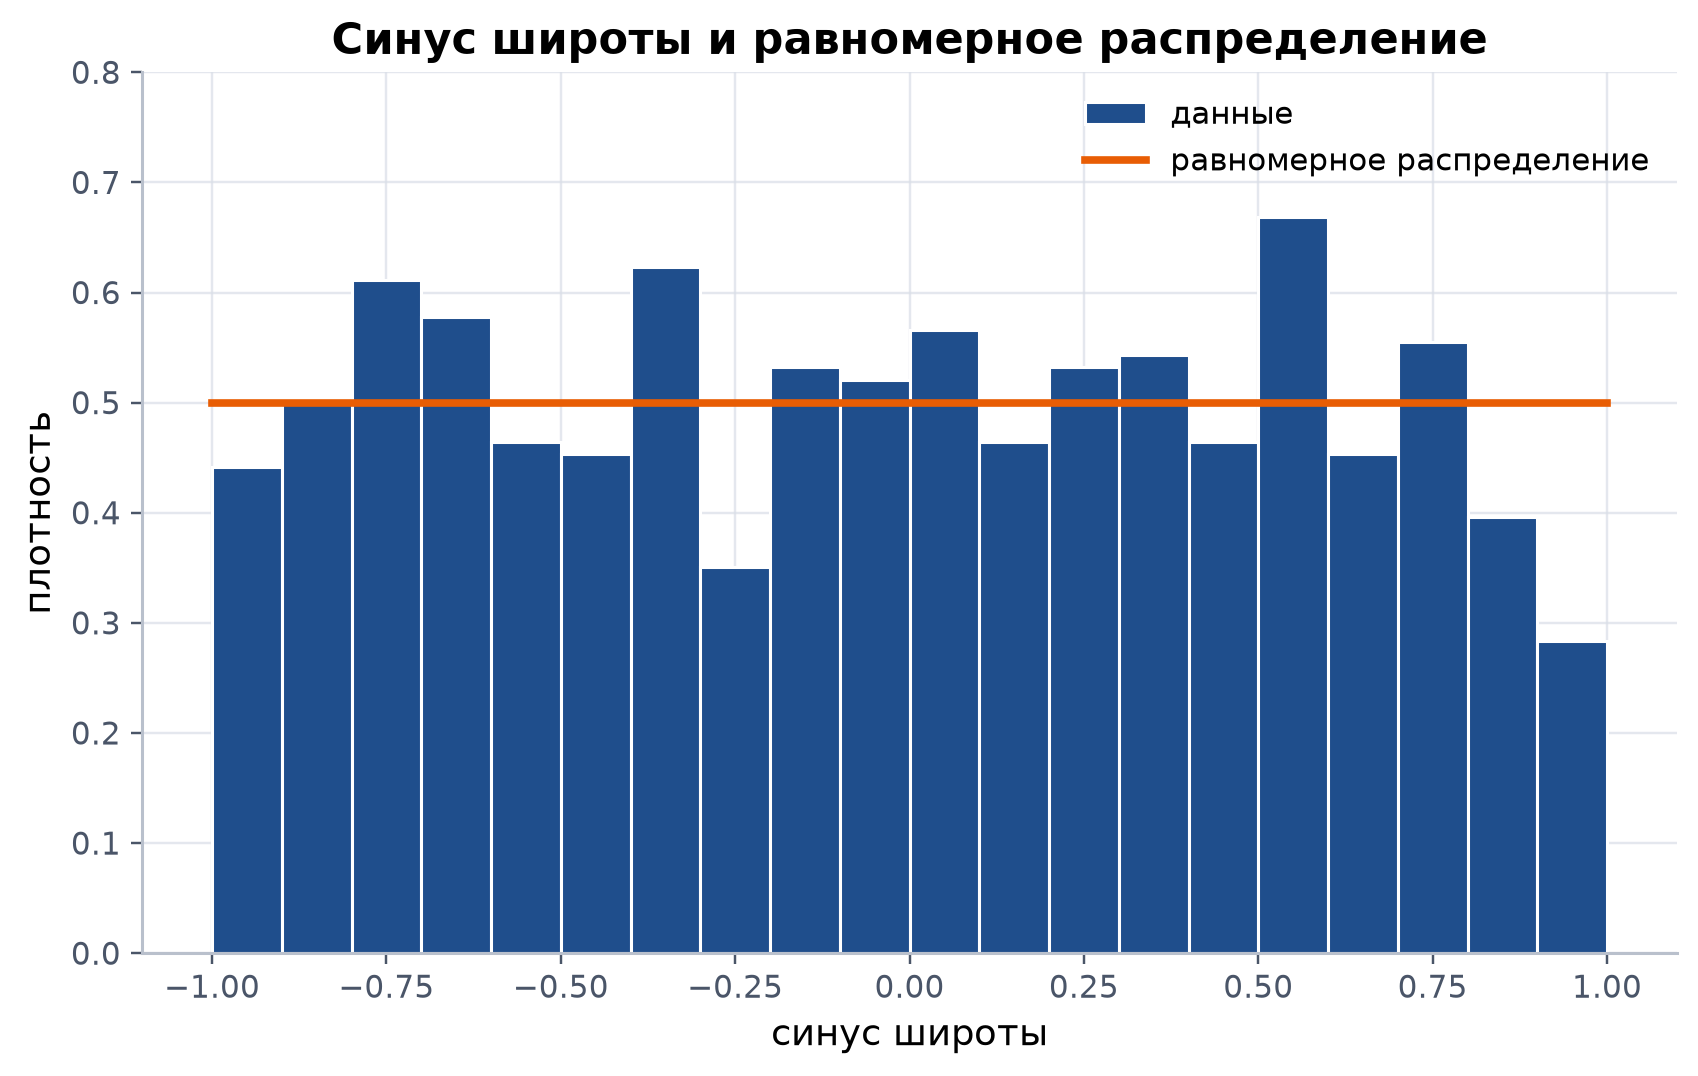

,по данным,по формулам
среднее,-0.023,0.000
дисперсия,0.316,0.333
асимметрия,-0.003,0.000


In [48]:
# гистограмма синуса широты и плотность равномерного распределения
plt.hist(sin_lat, bins=20, range=(-1, 1), density=True, color=C_DATA, edgecolor="white", label="данные")
plt.plot([-1, 1], [0.5, 0.5], color=C_THEORY, linewidth=2.5, label="равномерное распределение")
plt.title("Синус широты и равномерное распределение")
plt.xlabel("синус широты")
plt.ylabel("плотность")
plt.ylim(0, 0.8)
plt.legend()
plt.show()

compare_l = pd.DataFrame({
    "по данным": [sin_lat.mean(), sin_lat.var(), sin_lat.skew()],
    "по формулам": [0, 1 / 3, 0],
}, index=["среднее", "дисперсия", "асимметрия"])
compare_l.round(3)

Если болиды падают равномерно по всей Земле, то синус широты должен быть равномерным от -1 до 1. На графике столбики идут около оранжевой линии, где-то чуть выше, где-то чуть ниже. Числа тоже близко к формулам: среднее -0.023 вместо 0, дисперсия 0.316 вместо 0.333, асимметрия почти ноль. То есть похоже что болиды и правда падают куда попало.

#### Проверка гипотезы

$H_0$: синус широты распределен равномерно от $-1$ до $1$, то есть болиды падают равномерно по поверхности Земли.

$H_1$: распределение другое.

Уровень значимости $\alpha = 0.05$. Проверяем критерием Колмогорова-Смирнова. Параметры тут по данным не оценивались, границы $-1$ и $1$ известны заранее.

статистика D: 0.0366
p-value: 0.184


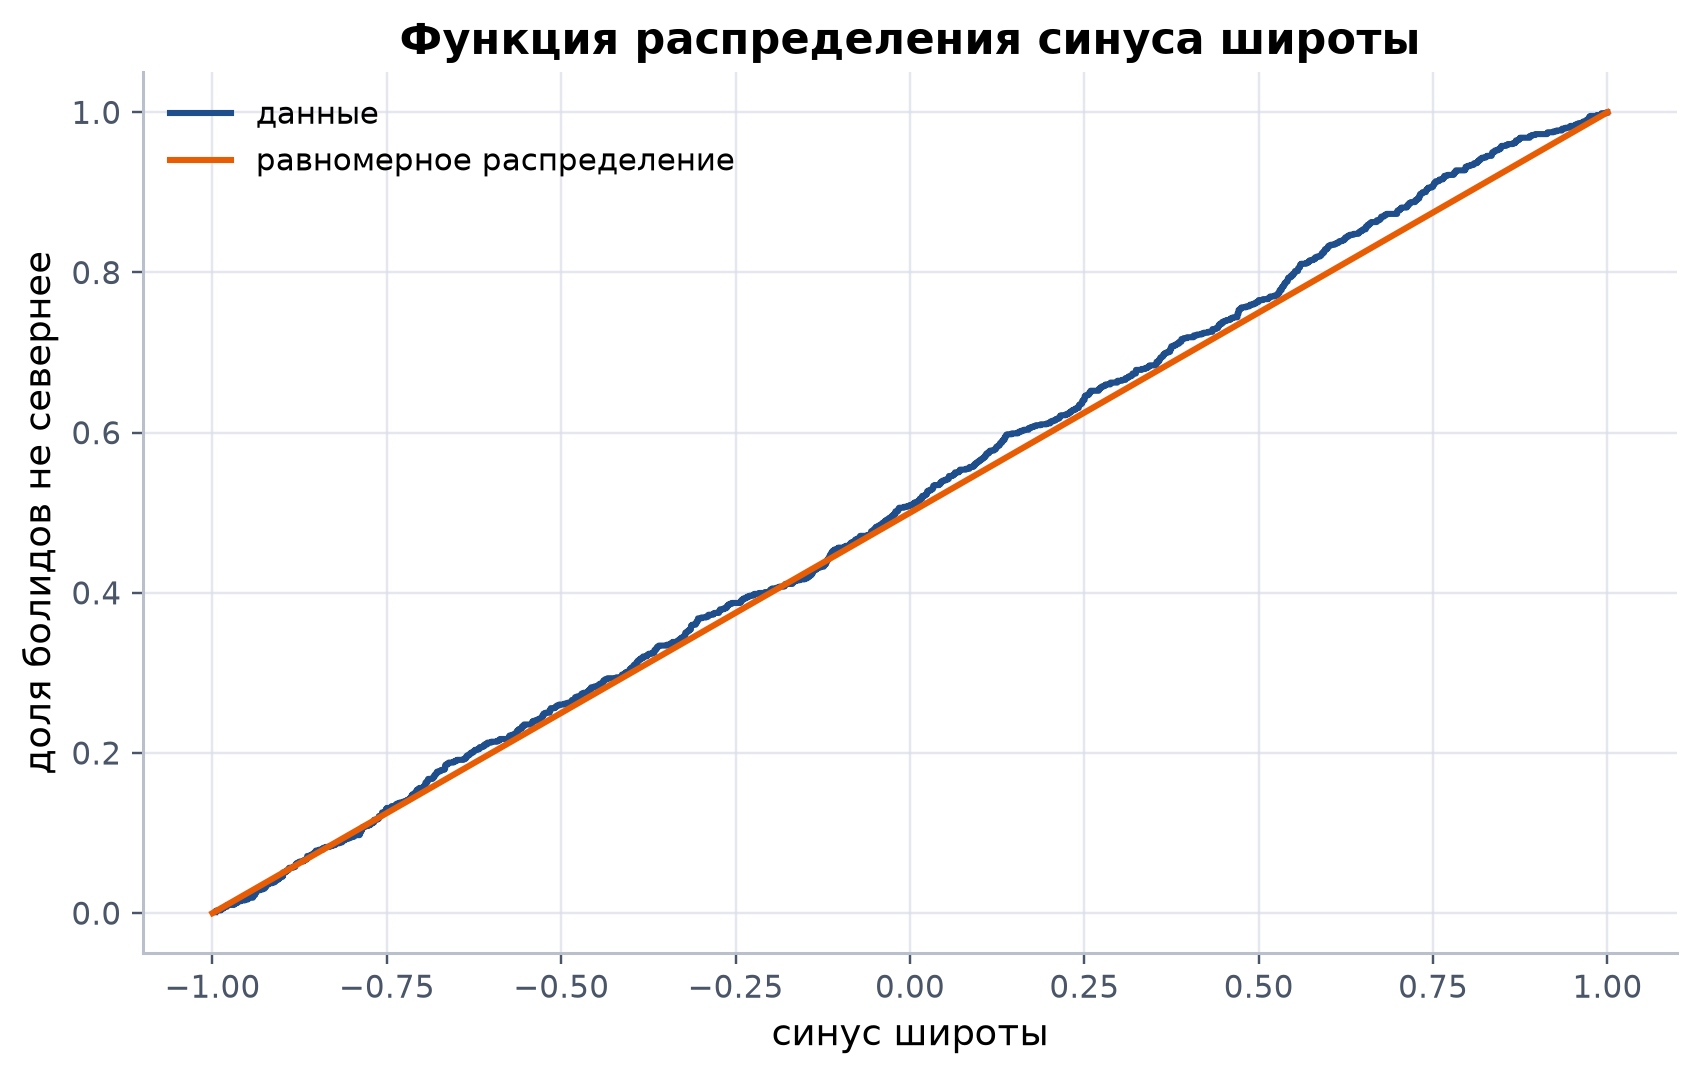

In [49]:
# args=(-1, 2): начало отрезка -1 и его длина 2
D_l, p_value_l = stats.kstest(sin_lat, "uniform", args=(-1, 2))
print("статистика D:", round(D_l, 4))
print("p-value:", round(p_value_l, 3))

sorted_sin = np.sort(sin_lat)
plt.step(sorted_sin, np.arange(1, len(sin_lat) + 1) / len(sin_lat), color=C_DATA, label="данные")
plt.plot([-1, 1], [0, 1], color=C_THEORY, label="равномерное распределение")
plt.title("Функция распределения синуса широты")
plt.xlabel("синус широты")
plt.ylabel("доля болидов не севернее")
plt.legend()
plt.show()

Проверяли что синус широты распределен равномерно, то есть что болиды падают равномерно по поверхности Земли. Взяли критерий Колмогорова-Смирнова. Статистика D получилась 0.0366, на графике ступенчатая линия идет почти по прямой. P-value 0.184, это больше 0.05, гипотезу не отвергаем. Тут в отличие от интервалов мы ничего не считали по данным, границы -1 и 1 известны заранее. Получается у Земли нет места куда болиды падают чаще.

### Independence & Estimations

Широта другой природы чем интервалы и число за месяц: она про место, а не про время. Связь широты с интервалом проверена выше в разделе про случайность.

#### Выборка и генеральная совокупность

Генеральная совокупность это все болиды с известной широтой. Берем выборку из 200 без возвращения и с возвращением, считаем по синусу широты.

           все болиды  выборка без возвращения  выборка с возвращением
среднее        -0.023                   -0.083                  -0.013
медиана        -0.021                   -0.113                   0.033
дисперсия       0.316                    0.303                   0.350


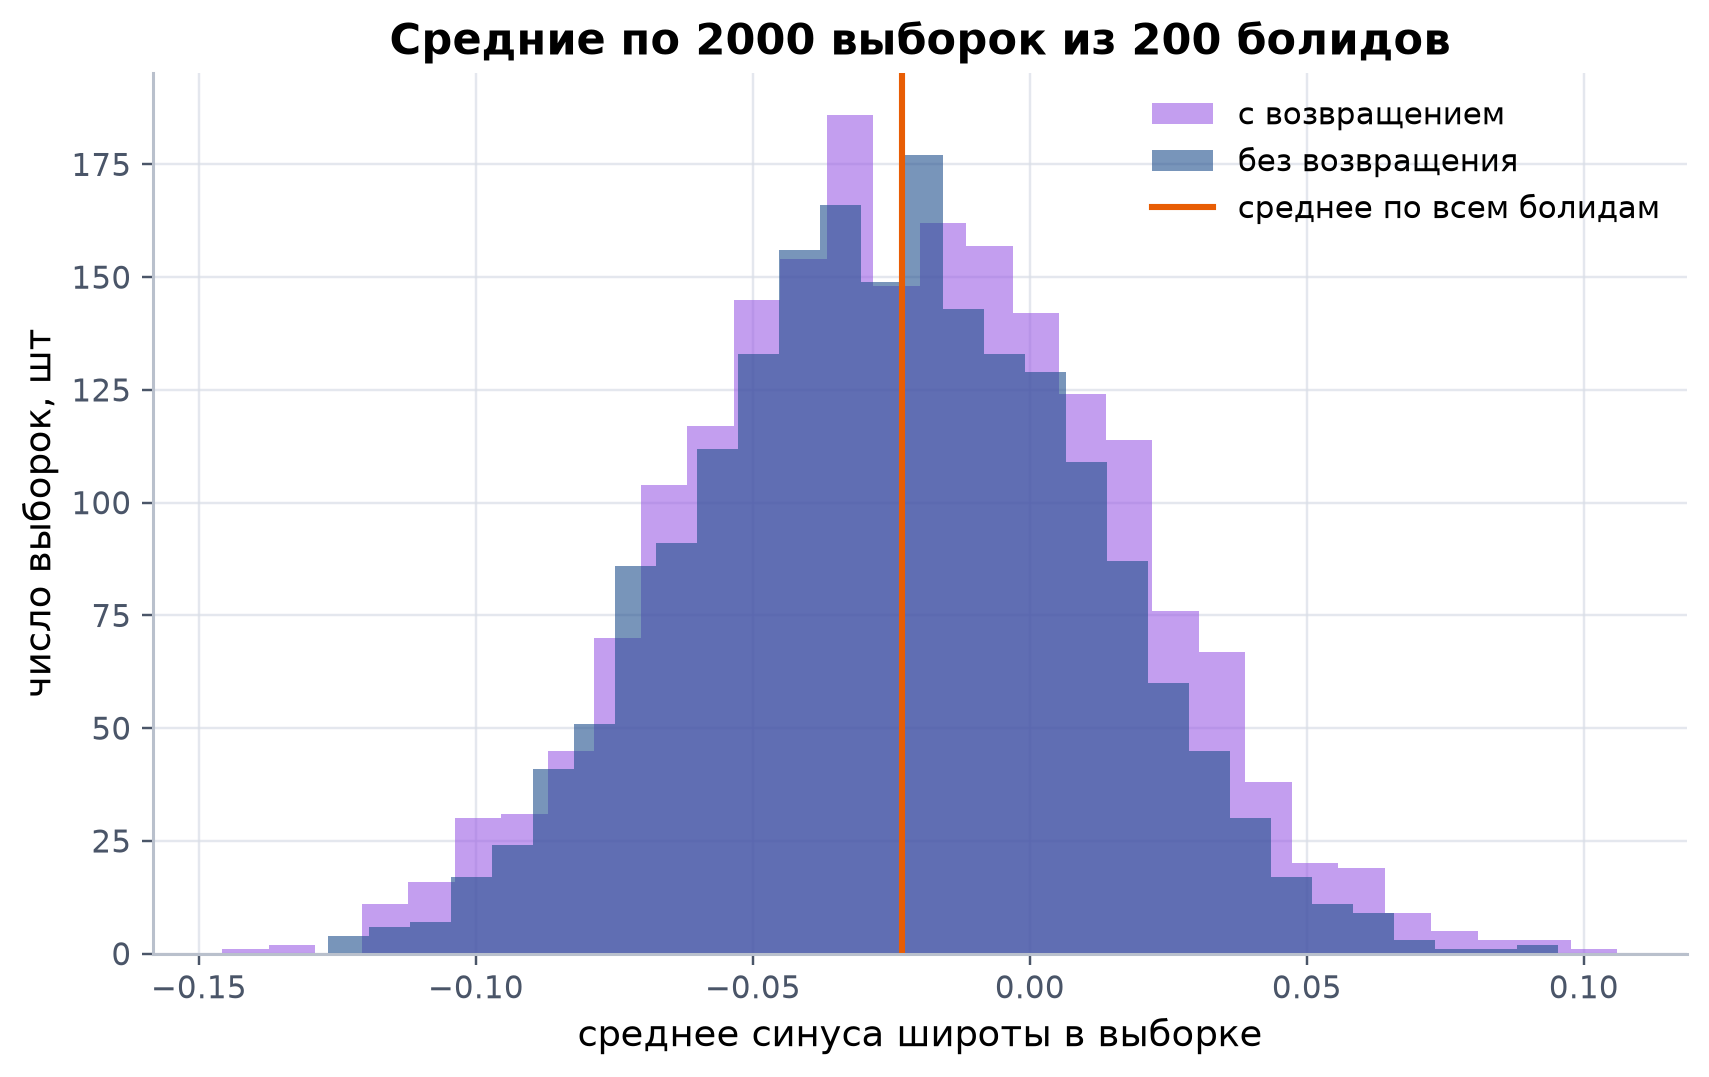

среднее по всем болидам: -0.023
без возвращения: среднее средних -0.025  разброс (ст. отклонение) 0.035
с возвращением:  среднее средних -0.023  разброс (ст. отклонение) 0.038


In [50]:
n_l = 200
sin_series = pd.Series(sin_lat)

sample_without_l = sin_series.sample(n_l, replace=False, random_state=1)
sample_with_l = sin_series.sample(n_l, replace=True, random_state=1)

sample_table_l = pd.DataFrame({
    "все болиды": [sin_series.mean(), sin_series.median(), sin_series.var()],
    "выборка без возвращения": [sample_without_l.mean(), sample_without_l.median(), sample_without_l.var()],
    "выборка с возвращением": [sample_with_l.mean(), sample_with_l.median(), sample_with_l.var()],
}, index=["среднее", "медиана", "дисперсия"])
print(sample_table_l.round(3))

means_without_l = [sin_series.sample(n_l, replace=False, random_state=i).mean() for i in range(2000)]
means_with_l = [sin_series.sample(n_l, replace=True, random_state=i).mean() for i in range(2000)]

plt.hist(means_with_l, bins=30, alpha=0.6, color=C_ACCENT, label="с возвращением")
plt.hist(means_without_l, bins=30, alpha=0.6, color=C_DATA, label="без возвращения")
plt.axvline(sin_series.mean(), color=C_THEORY, label="среднее по всем болидам")
plt.title("Средние по 2000 выборок из 200 болидов")
plt.xlabel("среднее синуса широты в выборке")
plt.ylabel("число выборок, шт")
plt.legend()
plt.show()

print("среднее по всем болидам:", round(sin_series.mean(), 3))
print("без возвращения: среднее средних", round(np.mean(means_without_l), 3), " разброс (ст. отклонение)", round(np.std(means_without_l), 3))
print("с возвращением:  среднее средних", round(np.mean(means_with_l), 3), " разброс (ст. отклонение)", round(np.std(means_with_l), 3))

Выборка из 200 болидов похожа на все данные: среднее -0.083 и -0.013 при настоящем -0.023, дисперсия 0.303 и 0.350 при 0.316. Все эти числа около нуля, так что разница маленькая. По 2000 выборок средние лежат вокруг -0.025 и -0.023, то есть где и надо. Разброс без возвращения опять чуть меньше (0.035 против 0.038). По выборке судить о всех болидах можно.

#### Состоятельность оценок

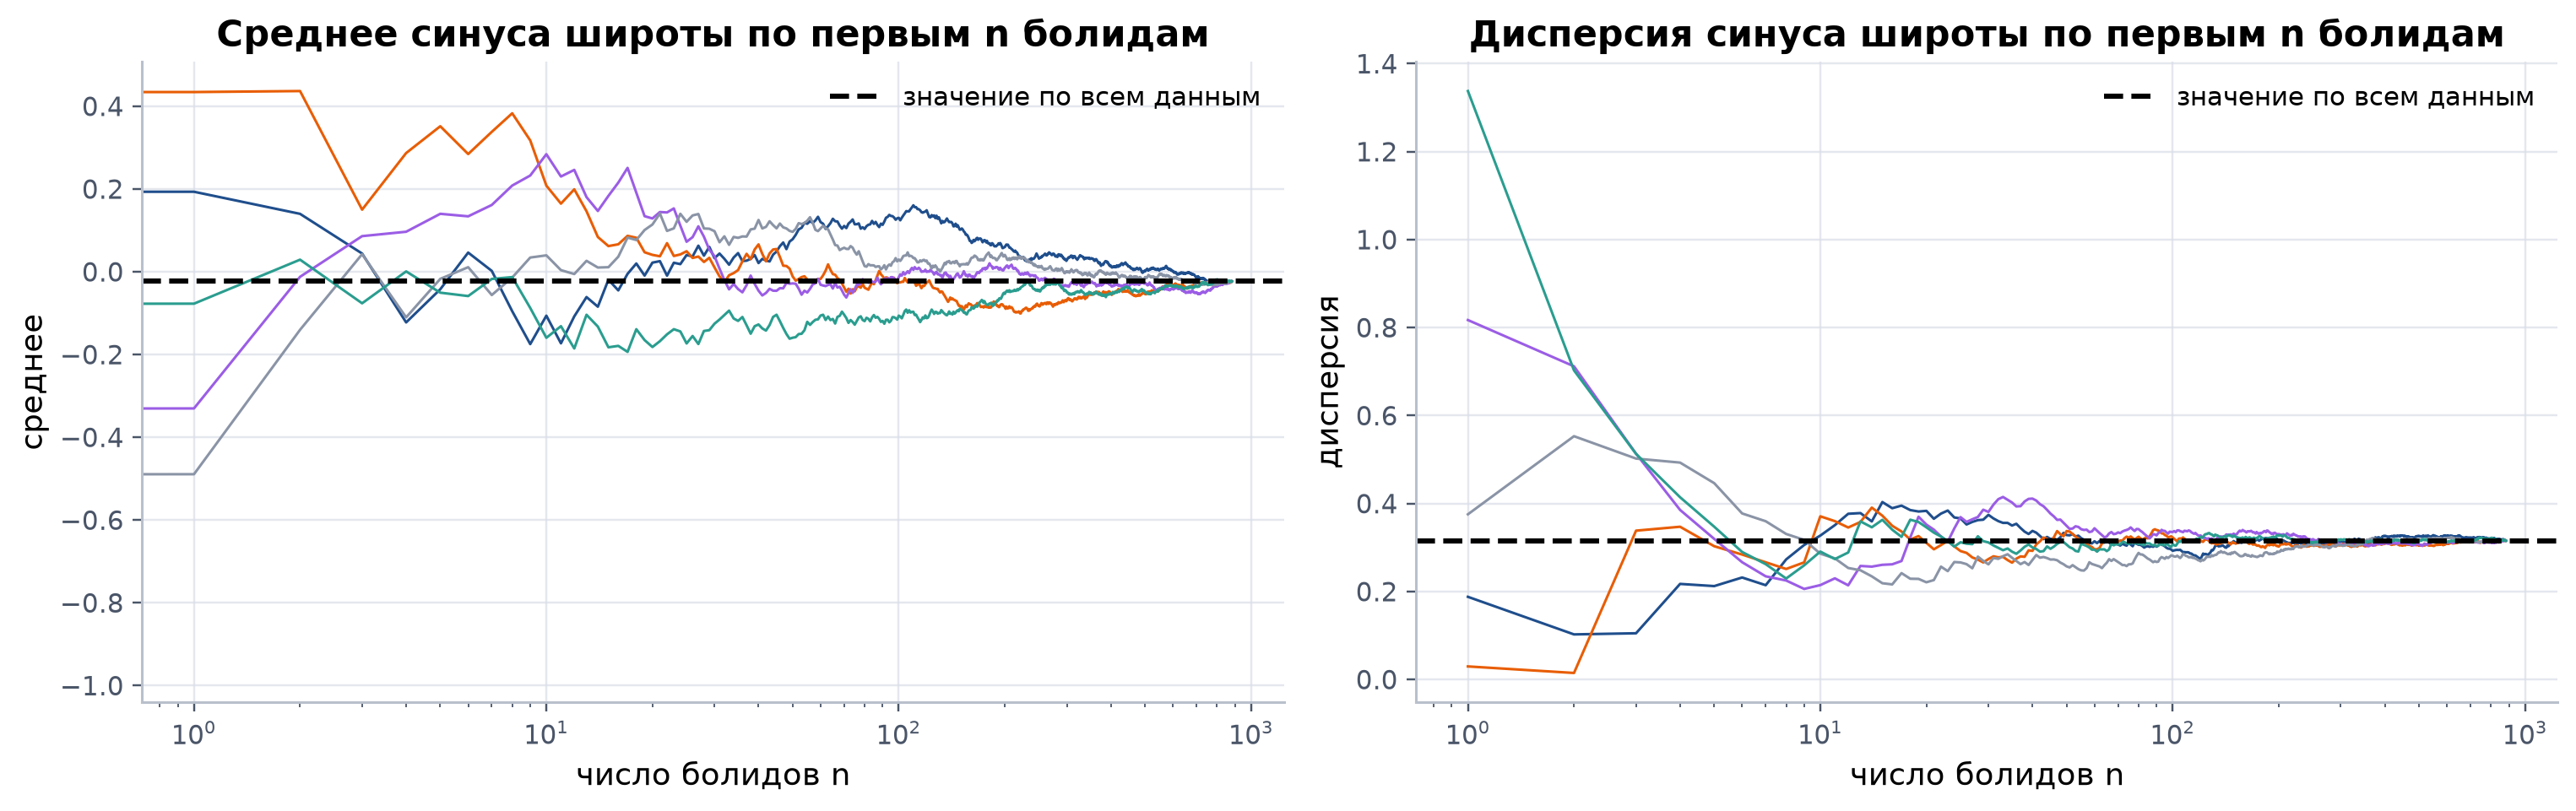

n = 10  среднее: -0.175  дисперсия: 0.306
n = 50  среднее: 0.073  дисперсия: 0.333
n = 200  среднее: 0.059  дисперсия: 0.318
n = 500  среднее: 0.001  дисперсия: 0.327
n = 883  среднее: -0.023  дисперсия: 0.316


In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for seed in range(5):
    shuffled_l = sin_series.sample(frac=1, random_state=seed).reset_index(drop=True)
    axes[0].plot(shuffled_l.expanding().mean(), linewidth=1)
    axes[1].plot(shuffled_l.expanding().var(), linewidth=1)

axes[0].axhline(sin_series.mean(), color="black", linestyle="--", label="значение по всем данным")
axes[0].set_title("Среднее синуса широты по первым n болидам")
axes[0].set_ylabel("среднее")
axes[1].axhline(sin_series.var(), color="black", linestyle="--", label="значение по всем данным")
axes[1].set_title("Дисперсия синуса широты по первым n болидам")
axes[1].set_ylabel("дисперсия")
for ax in axes:
    ax.set_xlabel("число болидов n")
    ax.set_xscale("log")
    ax.legend()
plt.tight_layout()
plt.show()

shuffled_l = sin_series.sample(frac=1, random_state=0).reset_index(drop=True)
for j in [10, 50, 200, 500, len(sin_series)]:
    print("n =", j, " среднее:", round(shuffled_l[:j].mean(), 3), " дисперсия:", round(shuffled_l[:j].var(), 3))

Когда болидов мало, линии скачут, среднее по первым десяти получилось -0.175. Дальше линии подходят к пунктиру. Среднее в конце -0.023, дисперсия 0.316. Дисперсия тут успокаивается быстро, уже на 50 болидах она 0.333. Обе оценки состоятельные.

## Lab resume

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
|        |               |       |         |

# Lab01 - sprint 2

## random 01

### Description

### math desc

### code

### tests

### resume

## Lab resume

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
|        |               |       |         |